# DIT5411: Chinese Handwritten Character Recognition

This notebook contains data preparation, preliminary diagnostics, validation experiments, and final training and testing for 13,065 Chinese character classes. The three final architectures are an ANN, a Simple CNN, and a Deep CNN.

## Results

| Model | Best validation accuracy | Final test accuracy |
|---|---:|---:|
| ANN | 34.05% | 29.52% |
| Simple CNN | 77.00% | 74.01% |
| Deep CNN | 92.32% | 90.01% |

Validation experiments and final test evaluation are separate stages. For final training, each model was initialized afresh and fitted on all 521,860 original training images. Final testing used 162,817 held-out images.

The final training and testing cell is self-contained once Google Drive is mounted and the prepared data are available. Earlier validation cells have dependencies: the corrected Simple CNN cell defines helper functions used by the ANN and Deep CNN cells. Historical diagnostic cells are retained for context and are excluded from the final comparison. Execute the required sections rather than using Run all.


## Model 3: Deep CNN Validation Training (Initial Three Epochs)

This model uses three convolutional blocks and saves its validation-stage results in `cnn_deep_validation_v1`. This initial cell sets `EPOCHS = 3`; a later section extends the experiment to six epochs.

The cell requires Google Drive, a detected GPU, and the helper functions and local cache defined by the corrected Simple CNN training cell.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (LeakyReLU)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,826,761 (10.78 MB)

 Trainable params: 2,826,761 (10.78 MB)

 Non-trainable params: 0 (0.00 B)

Training originals: 469700
Validation originals: 52160
Augmented views per epoch: 2613000
今次唔會讀取正式 test set。
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 400s 19ms/step - accuracy: 0.5358 - loss: 2.4474 - val_accuracy: 0.8261 - val_loss: 0.6297

Saved deep CNN epoch 1. Time: 7.4 min. Validation accuracy: 82.61%
Epoch 2/2
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 394s 19ms/step - accuracy: 0.8459 - loss: 0.5363 - val_accuracy: 0.8857 - val_loss: 0.4084

Saved deep CNN epoch 2. Time: 6.6 min. Validation accuracy: 88.57%
Epoch 3/3
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 398s 19ms/step - accuracy: 0.8937 - loss: 0.3569 - val_accuracy: 0.8888 - val_loss: 0.4036

Saved deep CNN epoch 3. Time: 7.4 min. Validation accuracy: 88.88%


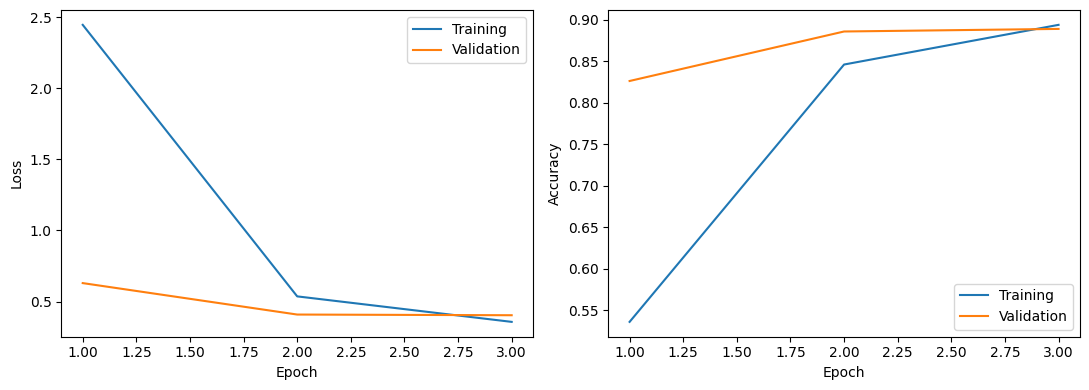


Completed epochs: 3
Best deep CNN validation accuracy: 88.88% (epoch 3)
Saved to: /content/drive/MyDrive/DIT5411/runs/cnn_deep_validation_v1

===== 三個模型比較：Validation =====
ANN: 34.05% (epoch 3)
Simple CNN: 77.00% (epoch 3)
Deep CNN: 88.88% (epoch 3)

以上仍然係 validation，未係最終 test accuracy。


In [5]:
# ===== Model 3：較深 CNN =====

from pathlib import Path
import csv
import hashlib
import json
import math
import shutil
import time

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, mixed_precision


def train_deeper_cnn():
    PROJECT = Path("/content/drive/MyDrive/DIT5411")
    CACHE = Path("/content/dit5411_cache")
    RUN = PROJECT / "runs" / "cnn_deep_validation_v1"

    EPOCHS = 3
    BATCH_SIZE = 128
    NUM_CLASSES = 13065
    VIEWS = 200
    SEED = 42

    assert tf.config.list_physical_devices("GPU"), (
        "請先連接 T4 GPU"
    )
    assert (PROJECT / "split_manifest.csv").is_file(), (
        "請先連接 Google Drive"
    )

    # 沿用之前完整訓練格定義嘅輔助函數
    helpers = [
        "validation_partition",
        "epoch_plan",
        "atomic_json",
        "completed_records"
    ]
    missing = [name for name in helpers if name not in globals()]
    assert not missing, (
        f"缺少輔助函數：{missing}。"
        "如果剛重設執行階段，請先還原新版 v2 訓練格嘅函數。"
    )

    assert (CACHE / "ready.json").is_file(), (
        "本機圖片快取不存在，請先還原訓練資料"
    )

    digest = hashlib.sha256(
        (PROJECT / "split_manifest.csv").read_bytes()
    ).hexdigest()

    cache_config = json.loads(
        (CACHE / "ready.json").read_text()
    )
    assert cache_config["manifest_sha256"] == digest

    # 重用本機磁碟陣列，唔重新下載或解壓
    x = np.load(
        CACHE / "train_images.npy",
        mmap_mode="r"
    )
    y = np.load(
        CACHE / "train_labels.npy",
        mmap_mode="r"
    )

    assert x.shape == (521860, 64, 64, 1)
    assert x.dtype == np.uint8
    assert y.shape == (521860,)

    train_groups, val_indices = validation_partition(
        y, NUM_CLASSES, SEED
    )

    # 確認同簡單 CNN 使用完全相同嘅 validation 圖片
    reference_partition = (
        PROJECT / "runs" / "cnn_small_validation_v2"
        / "validation_indices.npz"
    )
    with np.load(
        reference_partition, allow_pickle=False
    ) as saved:
        assert np.array_equal(
            saved["indices"], val_indices
        ), "Validation 分組不一致"

    assert sum(map(len, train_groups)) == 469700
    assert len(val_indices) == 52160

    tf.keras.backend.clear_session()
    mixed_precision.set_global_policy("mixed_float16")
    tf.keras.utils.set_random_seed(SEED)

    config = {
        "experiment": "cnn_deep_validation_v1",
        "manifest_sha256": digest,
        "tensorflow": tf.__version__,
        "architecture": (
            "conv32_pool_conv64_pool_conv128_pool_"
            "flatten_dense128_dropout02_softmax"
        ),
        "input_size": 64,
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
        "views_per_class_per_epoch": VIEWS,
        "validation_source": "cnn_small_validation_v2",
        "validation_indices_sha256": hashlib.sha256(
            val_indices.tobytes()
        ).hexdigest(),
        "seed": SEED,
        "sampling_seed_base": SEED + 1000,
        "precision": "mixed_float16",
        "input_transform": "1_minus_pixel_div_255_float32",
        "augmentation": {
            "rotation_factor": 0.025,
            "translation": 0.05,
            "zoom": 0.1,
            "fill_mode": "constant",
            "fill_value": 0
        },
        "activation": "LeakyReLU",
        "negative_slope": 0.1,
        "kernel_initializer": "he_normal",
        "dropout": 0.2,
        "optimizer": "Adam",
        "learning_rate": 0.0003,
        "clipnorm": 1.0
    }

    config_hash = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()

    RUN.mkdir(parents=True, exist_ok=True)
    config_file = RUN / "config.json"

    if config_file.exists():
        assert json.loads(config_file.read_text()) == config, (
            "實驗設定改變，請先檢查，唔好覆蓋舊 checkpoint"
        )
    else:
        atomic_json(config_file, config)

    # 保存分組副本
    partition_path = RUN / "validation_indices.npz"
    if partition_path.exists():
        with np.load(
            partition_path, allow_pickle=False
        ) as saved:
            assert np.array_equal(
                saved["indices"], val_indices
            )
    else:
        temporary = CACHE / "deep_validation_indices.npz"
        np.savez_compressed(
            temporary, indices=val_indices
        )
        shutil.copyfile(temporary, partition_path)

    def make_dataset(indices):
        def batches():
            for start in range(
                0, len(indices), BATCH_SIZE
            ):
                selected = indices[
                    start:start + BATCH_SIZE
                ]
                yield (
                    np.asarray(x[selected]),
                    np.asarray(
                        y[selected], dtype=np.int32
                    )
                )

        dataset = tf.data.Dataset.from_generator(
            batches,
            output_signature=(
                tf.TensorSpec(
                    (None, 64, 64, 1), tf.uint8
                ),
                tf.TensorSpec(
                    (None,), tf.int32
                )
            )
        )
        dataset = dataset.apply(
            tf.data.experimental.assert_cardinality(
                math.ceil(
                    len(indices) / BATCH_SIZE
                )
            )
        )
        return dataset.prefetch(2)

    records = completed_records(RUN, config_hash)
    start_epoch = len(records)

    if records:
        checkpoint = RUN / records[-1]["model_file"]
        print("恢復模型：", checkpoint.name)
        model = tf.keras.models.load_model(checkpoint)

    else:
        model = tf.keras.Sequential([
            layers.Input(shape=(64, 64, 1)),

            layers.Rescaling(
                -1.0 / 255,
                offset=1.0,
                dtype="float32"
            ),
            layers.RandomRotation(
                0.025,
                fill_mode="constant",
                fill_value=0,
                seed=SEED
            ),
            layers.RandomTranslation(
                0.05, 0.05,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 1
            ),
            layers.RandomZoom(
                0.1,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 2
            ),

            # 卷積區塊 1：64×64 -> 32×32
            layers.Conv2D(
                32, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            # 卷積區塊 2：32×32 -> 16×16
            layers.Conv2D(
                64, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            # 卷積區塊 3：16×16 -> 8×8
            layers.Conv2D(
                128, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            layers.Flatten(),
            layers.Dense(
                128,
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(
                negative_slope=0.1,
                name="features"
            ),
            layers.Dropout(0.2),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax",
                dtype="float32"
            )
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.0003,
                clipnorm=1.0
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
            jit_compile=False
        )

    model.summary()

    with (RUN / "model_summary.txt").open("w") as f:
        model.summary(
            print_fn=lambda line, **kwargs: f.write(
                line + "\n"
            )
        )

    print("Training originals:", sum(map(len, train_groups)))
    print("Validation originals:", len(val_indices))
    print("Augmented views per epoch:", NUM_CLASSES * VIEWS)
    print("今次唔會讀取正式 test set。")

    steps = math.ceil(
        NUM_CLASSES * VIEWS / BATCH_SIZE
    )
    val_steps = math.ceil(
        len(val_indices) / BATCH_SIZE
    )
    validation_data = make_dataset(val_indices)

    for epoch in range(start_epoch, EPOCHS):
        # 同簡單 CNN 使用相同原圖抽樣次序
        plan = epoch_plan(
            train_groups,
            VIEWS,
            SEED + 1000 + epoch
        )

        assert np.all(
            np.bincount(
                y[plan],
                minlength=NUM_CLASSES
            ) == VIEWS
        )

        started = time.perf_counter()

        result = model.fit(
            make_dataset(plan),
            validation_data=validation_data,
            initial_epoch=epoch,
            epochs=epoch + 1,
            steps_per_epoch=steps,
            validation_steps=val_steps,
            callbacks=[
                tf.keras.callbacks.TerminateOnNaN()
            ],
            verbose=1
        )

        metrics = {
            key: float(value[-1])
            for key, value in result.history.items()
        }
        assert "val_accuracy" in metrics
        assert all(
            np.isfinite(value)
            for value in metrics.values()
        ), "出現非有限數值，停止保存本輪模型"

        elapsed = time.perf_counter() - started

        filename = f"epoch_{epoch + 1:03d}.keras"
        local_model = CACHE / f"deep_{filename}"
        model.save(local_model)

        partial = RUN / (filename + ".partial")
        shutil.copyfile(local_model, partial)

        assert (
            partial.stat().st_size
            == local_model.stat().st_size
        )

        partial.replace(RUN / filename)
        local_model.unlink()

        record = {
            "epoch": epoch + 1,
            "config_hash": config_hash,
            "model_file": filename,
            "fit_seconds": elapsed,
            **metrics
        }

        atomic_json(
            RUN / f"epoch_{epoch + 1:03d}.json",
            record
        )
        records.append(record)

        best = max(
            records,
            key=lambda row: row["val_accuracy"]
        )
        atomic_json(RUN / "best.json", best)

        # 每輪保存累積紀錄
        with (RUN / "history.csv").open(
            "w", newline=""
        ) as f:
            writer = csv.DictWriter(
                f, fieldnames=list(records[0])
            )
            writer.writeheader()
            writer.writerows(records)

        print(
            f"\nSaved deep CNN epoch {epoch + 1}. "
            f"Time: {elapsed / 60:.1f} min. "
            f"Validation accuracy: "
            f"{metrics['val_accuracy']:.2%}",
            flush=True
        )
        del plan

    # 畫圖
    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4)
    )
    epoch_numbers = [r["epoch"] for r in records]

    for ax, metric in zip(
        axes, ["loss", "accuracy"]
    ):
        ax.plot(
            epoch_numbers,
            [r[metric] for r in records],
            label="Training"
        )
        ax.plot(
            epoch_numbers,
            [r["val_" + metric] for r in records],
            label="Validation"
        )
        ax.set(
            xlabel="Epoch",
            ylabel=metric.title()
        )
        ax.legend()

    fig.tight_layout()
    fig.savefig(
        RUN / "learning_curves.png", dpi=150
    )
    plt.show()

    best = max(
        records,
        key=lambda row: row["val_accuracy"]
    )

    print("\nCompleted epochs:", len(records))
    print(
        f"Best deep CNN validation accuracy: "
        f"{best['val_accuracy']:.2%} "
        f"(epoch {best['epoch']})"
    )
    print("Saved to:", RUN)

    # 顯示目前三個模型嘅最佳 validation 結果
    print("\n===== 三個模型比較：Validation =====")
    experiments = [
        ("ANN", "ann_mlp_validation_v1"),
        ("Simple CNN", "cnn_small_validation_v2"),
        ("Deep CNN", "cnn_deep_validation_v1")
    ]

    for name, folder in experiments:
        best_path = PROJECT / "runs" / folder / "best.json"
        if best_path.exists():
            row = json.loads(best_path.read_text())
            print(
                f"{name}: {row['val_accuracy']:.2%} "
                f"(epoch {row['epoch']})"
            )

    print("\n以上仍然係 validation，未係最終 test accuracy。")


train_deeper_cnn()

## Check TensorFlow GPU Availability

Run this check before full training. TensorFlow should list a GPU device. An empty list (`[]`) means no GPU was detected.


In [2]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## First-Time Setup: Download the Character Dataset

Download and verify the 12 archive parts from GitHub. This preparation step is unnecessary when the prepared image shards are already available in Google Drive.


In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/handwritting_data_all")

if not repo.exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/chenkenanalytic/handwritting_data_all.git",
        str(repo)
    ], check=True)

parts = sorted(repo.glob("all_data.zip.[0-9][0-9][0-9]"))

print(f"已找到 {len(parts)} 個壓縮分卷")
for part in parts:
    print(part.name, f"{part.stat().st_size / 1024**2:.1f} MB")

assert len(parts) == 12, "分卷未齊，請檢查下載結果"

已找到 12 個壓縮分卷
all_data.zip.001 95.0 MB
all_data.zip.002 95.0 MB
all_data.zip.003 95.0 MB
all_data.zip.004 95.0 MB
all_data.zip.005 95.0 MB
all_data.zip.006 95.0 MB
all_data.zip.007 95.0 MB
all_data.zip.008 95.0 MB
all_data.zip.009 95.0 MB
all_data.zip.010 95.0 MB
all_data.zip.011 95.0 MB
all_data.zip.012 42.3 MB


## First-Time Setup: Extract and Inspect the Dataset

Decode Chinese filenames using CP950 and inspect the extracted images. This cell expects the archive parts to have been combined into `/content/all_data.zip`. The archive merge snippet is provided in the README.


In [ ]:
from pathlib import Path
import zipfile
from tqdm.auto import tqdm

zip_path = Path("/content/all_data.zip")
assert zip_path.is_file(), "搵唔到已合併嘅 ZIP"

# 改用 Windows Big5（CP950）處理中文檔名
with zipfile.ZipFile(zip_path, metadata_encoding="cp950") as archive:
    for member in tqdm(archive.infolist(), desc="解壓圖片"):
        archive.extract(member, "/content")

# 檢查資料
data_dir = Path("/content/cleaned_data")
assert data_dir.is_dir(), "搵唔到 cleaned_data 資料夾"

class_dirs = sorted(p for p in data_dir.iterdir() if p.is_dir())
extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

counts = [
    sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    )
    for folder in tqdm(class_dirs, desc="檢查資料")
]

print("\n字數：", len(class_dirs))
print("圖片總數：", sum(counts))
print("每字最少圖片數：", min(counts) if counts else 0)
print("少於 41 張圖片嘅字數：", sum(n < 41 for n in counts))
print("字名例子：", [p.name for p in class_dirs[:10]])

解壓圖片:   0%|          | 0/697743 [00:00<?, ?it/s]

檢查資料:   0%|          | 0/13065 [00:00<?, ?it/s]


字數： 13065
圖片總數： 684677
每字最少圖片數： 16
少於 41 張圖片嘅字數： 43
字名例子： ['1', '10', '100', '1000', '10000', '10001', '10002', '10003', '10004', '10005']


## Dataset Inspection: Small Classes and Original Image Format

Inspect the 43 classes with fewer than 41 images and check the dimensions and color mode of an example original image.


In [ ]:
from pathlib import Path
from PIL import Image

data_dir = Path("/content/cleaned_data")
extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

short_classes = []

for folder in sorted(p for p in data_dir.iterdir() if p.is_dir()):
    images = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    )
    if len(images) < 41:
        short_classes.append((folder.name, len(images), images[:2]))

print("少於 41 張嘅字數：", len(short_classes))

for label, count, examples in short_classes[:20]:
    print(label, count, [p.name for p in examples])

# 檢查其中一張圖片格式
sample = next(data_dir.rglob("*.png"))
with Image.open(sample) as img:
    print("\n範例圖片：", sample)
    print("圖片尺寸：", img.size)
    print("圖片模式：", img.mode)

少於 41 張嘅字數： 43
10020 33 ['飌_0.png', '飌_1.png']
10583 22 ['鴣_0.png', '鴣_1.png']
10647 37 ['鶄_0.png', '鶄_1.png']
11501 35 ['塥_0.png', '塥_1.png']
1678 32 ['楹_0.png', '楹_1.png']
1754 32 ['槳_0.png', '槳_1.png']
1917 22 ['櫰_0.png', '櫰_1.png']
2120 32 ['氠_0.png', '氠_1.png']
2138 32 ['氻_0.png', '氻_1.png']
2155 32 ['汕_0.png', '汕_1.png']
2271 31 ['泰_0.png', '泰_1.png']
23 36 ['仲_0.png', '仲_1.png']
2382 23 ['涒_0.png', '涒_1.png']
2565 31 ['溢_0.png', '溢_1.png']
2587 23 ['溿_0.png', '溿_1.png']
2742 23 ['澕_0.png', '澕_1.png']
3232 21 ['犆_0.png', '犆_1.png']
3582 18 ['璗_0.png', '璗_1.png']
4336 36 ['勯_0.png', '勯_1.png']
4366 18 ['匜_0.png', '匜_1.png']

範例圖片： /content/cleaned_data/6881/蘱_35.png
圖片尺寸： (300, 300)
圖片模式： RGB


## Mount Google Drive

Mount Google Drive so the notebook can access the prepared image shards, experiment records, and saved models.


In [1]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


## First-Time Setup: Create the Training/Test Split and Character Labels

Save `split_manifest.csv`, `labels.json`, and `split_exceptions.json`.

Classes with at least 41 images use the first 40 images for training and the remainder for testing. The 43 smaller classes use an approximately 80/20 split. This is a documented deviation from the assignment's literal first-40 rule. An existing partition does not need to be recreated.


In [ ]:
from pathlib import Path
import csv
import json
from collections import Counter
from tqdm.auto import tqdm

data_dir = Path("/content/cleaned_data")
save_dir = Path("/content/drive/MyDrive/DIT5411")
save_dir.mkdir(parents=True, exist_ok=True)

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# 資料夾按數字 ID 排序
folders = sorted(
    (p for p in data_dir.iterdir() if p.is_dir()),
    key=lambda p: int(p.name)
)
assert len(folders) == 13065

totals = Counter()
labels = []
exceptions = []

with (save_dir / "split_manifest.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow(["relative_path", "label", "character", "split"])

    for label, folder in enumerate(tqdm(folders, desc="建立分組清單")):
        images = sorted(
            (p for p in folder.iterdir()
             if p.is_file() and p.suffix.lower() in extensions),
            key=lambda p: int(p.stem.rsplit("_", 1)[1])
        )

        characters = {p.stem.rsplit("_", 1)[0] for p in images}
        assert len(characters) == 1, f"資料夾 {folder.name} 字名不一致"
        character = next(iter(characters))

        # 一般類別：頭 40 張訓練，其餘測試
        # 不足 41 張：採用約 80/20，保留測試樣本
        n_train = 40 if len(images) >= 41 else int(len(images) * 0.8)

        labels.append({
            "label": label,
            "folder_id": folder.name,
            "character": character
        })

        if len(images) < 41:
            exceptions.append({
                "folder_id": folder.name,
                "character": character,
                "total": len(images),
                "train": n_train,
                "test": len(images) - n_train
            })

        for i, image in enumerate(images):
            split = "train" if i < n_train else "test"
            writer.writerow([
                image.relative_to(data_dir).as_posix(),
                label, character, split
            ])
            totals[split] += 1

assert sum(totals.values()) == 684677

for filename, content in [
    ("labels.json", labels),
    ("split_exceptions.json", exceptions)
]:
    (save_dir / filename).write_text(
        json.dumps(content, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

print("\n類別數：", len(labels))
print("原始訓練圖片：", totals["train"])
print("測試圖片：", totals["test"])
print("樣本不足嘅例外類別：", len(exceptions))
print("已保存至：", save_dir)
print("頭 5 個標籤：", labels[:5])

建立分組清單:   0%|          | 0/13065 [00:00<?, ?it/s]


類別數： 13065
原始訓練圖片： 521860
測試圖片： 162817
樣本不足嘅例外類別： 43
已保存至： /content/drive/MyDrive/DIT5411
頭 5 個標籤： [{'label': 0, 'folder_id': '1', 'character': '一'}, {'label': 1, 'folder_id': '2', 'character': '不'}, {'label': 2, 'folder_id': '3', 'character': '仔'}, {'label': 3, 'folder_id': '4', 'character': '仕'}, {'label': 4, 'folder_id': '5', 'character': '他'}]


## First-Time Setup: Resize to 64-Pixel Grayscale Images and Save Shards

Convert the images to 64 × 64 grayscale to reduce RAM usage and computational cost within Google Colab's resource limits. Resizing may remove fine stroke details, making similar characters harder to distinguish.

Save 64 training shards and 20 test shards in the Google Drive `images_64` directory. This step does not need to be repeated once the prepared shards are available.


In [ ]:
from pathlib import Path
from PIL import Image
from itertools import islice
from tqdm.auto import tqdm
import numpy as np
import csv
import json
import hashlib
import shutil

project = Path("/content/drive/MyDrive/DIT5411")
manifest = project / "split_manifest.csv"
data_dir = Path("/content/cleaned_data")
output_dir = project / "images_64"
local_dir = Path("/content/dit5411_temp")

assert manifest.is_file(), "搵唔到分組清單"
assert data_dir.is_dir(), "搵唔到已解壓圖片"

output_dir.mkdir(parents=True, exist_ok=True)
local_dir.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 64
SHARD_SIZE = 8192  # 每個檔案最多存 8,192 張圖片

# 記錄設定，避免恢復執行時混用不同版本
config = {
    "image_size": IMAGE_SIZE,
    "shard_size": SHARD_SIZE,
    "manifest_sha256": hashlib.sha256(manifest.read_bytes()).hexdigest(),
    "pixel_format": "uint8_grayscale",
}

config_path = output_dir / "config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, \
        "設定同之前不同，請停止並檢查"
else:
    config_path.write_text(json.dumps(config, indent=2))

def selected_rows(split):
    with manifest.open(encoding="utf-8", newline="") as f:
        for source_id, row in enumerate(csv.DictReader(f)):
            if row["split"] == split:
                yield source_id, row

expected_counts = {"train": 521860, "test": 162817}
summary = {}

for split, expected in expected_counts.items():
    rows = selected_rows(split)
    total = 0
    shard_count = (expected + SHARD_SIZE - 1) // SHARD_SIZE

    for shard_id in tqdm(range(shard_count), desc=f"處理 {split}"):
        batch = list(islice(rows, SHARD_SIZE))
        assert batch, "清單圖片數少於預期"

        destination = output_dir / f"{split}_{shard_id:03d}.npz"
        labels = np.array([int(r["label"]) for _, r in batch],
                          dtype=np.int32)
        source_ids = np.array([i for i, _ in batch], dtype=np.int64)

        # 已完成嘅分片會檢查後跳過，方便中斷後重跑
        if destination.exists():
            with np.load(destination, allow_pickle=False) as saved:
                assert saved["images"].shape == (
                    len(batch), IMAGE_SIZE, IMAGE_SIZE, 1
                )
                assert saved["images"].dtype == np.uint8
                assert np.array_equal(saved["labels"], labels)
                assert np.array_equal(saved["source_ids"], source_ids)
        else:
            images = np.empty(
                (len(batch), IMAGE_SIZE, IMAGE_SIZE, 1),
                dtype=np.uint8
            )

            for j, (_, row) in enumerate(batch):
                path = data_dir / row["relative_path"]
                with Image.open(path) as image:
                    image = image.convert("L").resize(
                        (IMAGE_SIZE, IMAGE_SIZE),
                        Image.Resampling.LANCZOS
                    )
                    images[j, :, :, 0] = np.asarray(image)

            # 先喺 Colab 本機壓縮，再複製去 Drive
            temporary = local_dir / destination.name
            np.savez_compressed(
                temporary,
                images=images,
                labels=labels,
                source_ids=source_ids
            )

            partial = destination.with_suffix(".npz.partial")
            shutil.copyfile(temporary, partial)
            partial.replace(destination)
            temporary.unlink()

        total += len(batch)

    assert next(rows, None) is None, "清單圖片數多於預期"
    assert total == expected
    summary[split] = {"images": total, "shards": shard_count}

(output_dir / "summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\n處理完成：", summary)
print("已備份至：", output_dir)
print("備份大小：",
      round(sum(p.stat().st_size for p in output_dir.glob("*.npz"))
            / 1024**3, 2), "GB")

處理 train:   0%|          | 0/64 [00:00<?, ?it/s]

處理 test:   0%|          | 0/20 [00:00<?, ?it/s]


處理完成： {'train': {'images': 521860, 'shards': 64}, 'test': {'images': 162817, 'shards': 20}}
已備份至： /content/drive/MyDrive/DIT5411/images_64
備份大小： 0.44 GB


## Environment Setup: Copy Image Shards and Check the GPU

Copy the prepared image shards to Colab's local storage and verify their format. The corrected Simple CNN training cell can also prepare the required local training shards.


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

import tensorflow as tf
from pathlib import Path
import json
import numpy as np
import shutil

print("GPU:", tf.config.list_physical_devices("GPU"))

drive_dir = Path("/content/drive/MyDrive/DIT5411/images_64")
local_dir = Path("/content/images_64")

if not local_dir.exists():
    shutil.copytree(drive_dir, local_dir)

print("本機分片數：", len(list(local_dir.glob("*.npz"))))
print("設定：", json.loads((local_dir / "config.json").read_text()))

sample = sorted(local_dir.glob("train_*.npz"))[0]
with np.load(sample, allow_pickle=False) as data:
    print("圖片形狀：", data["images"].shape)
    print("標籤形狀：", data["labels"].shape)
    print("資料類型：", data["images"].dtype)

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
本機分片數： 84
設定： {'image_size': 64, 'shard_size': 8192, 'manifest_sha256': '1e7d55ea924c51f42823167a86493a32fe6316a9d5ffa1d93ea10388cfd5afc6', 'pixel_format': 'uint8_grayscale'}
圖片形狀： (8192, 64, 64, 1)
標籤形狀： (8192,)
資料類型： uint8


## Preliminary Benchmark: T4 GPU Training Speed

Run a 100-batch benchmark for debugging and estimating training time. Its accuracy is not a formal experimental result. This benchmark is not required for the final evaluation.


In [ ]:
import time
import math
import json
import numpy as np
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, mixed_precision

assert tf.config.list_physical_devices("GPU"), "未連接 GPU"

# T4 可以使用混合精度，減少顯示記憶體用量
tf.keras.backend.clear_session()
mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(42)

BATCH_SIZE = 128
NUM_CLASSES = 13065

# 只讀一個訓練分片做速度測試，唔使用測試資料
sample_path = sorted(Path("/content/images_64").glob("train_*.npz"))[0]

with np.load(sample_path, allow_pickle=False) as data:
    images = data["images"].copy()
    labels = data["labels"].copy()

assert images.shape[1:] == (64, 64, 1)
assert images.dtype == np.uint8
assert labels.min() >= 0 and labels.max() < NUM_CLASSES

dataset = (
    tf.data.Dataset.from_tensor_slices((images, labels))
    .shuffle(len(labels), seed=42)
    .repeat()
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 簡單 CNN，稍後可以作為正式比較嘅其中一個模型
model = tf.keras.Sequential([
    layers.Input(shape=(64, 64, 1)),
    layers.Rescaling(1.0 / 255),

    layers.RandomRotation(0.025, fill_mode="nearest"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="nearest"),
    layers.RandomZoom(0.1, fill_mode="nearest"),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # 混合精度下，輸出層保持 float32
    layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

model.summary()

class SpeedTimer(tf.keras.callbacks.Callback):
    def on_train_batch_begin(self, batch, logs=None):
        # 頭 10 批用作暖機，唔計入速度
        if batch == 10:
            self.started = time.perf_counter()

    def on_train_batch_end(self, batch, logs=None):
        if batch == 99:
            self.seconds_per_batch = (
                time.perf_counter() - self.started
            ) / 90

timer = SpeedTimer()

model.fit(
    dataset,
    epochs=1,
    steps_per_epoch=100,
    callbacks=[timer],
    verbose=1
)

# 以每類 200 個訓練樣本作粗略估算
estimated_steps = math.ceil(NUM_CLASSES * 200 / BATCH_SIZE)
estimated_minutes = estimated_steps * timer.seconds_per_batch / 60

result = {
    "batch_size": BATCH_SIZE,
    "seconds_per_batch": timer.seconds_per_batch,
    "estimated_training_minutes_per_epoch": estimated_minutes
}

save_path = Path("/content/drive/MyDrive/DIT5411/speed_test.json")
save_path.write_text(json.dumps(result, indent=2))

print(f"\n每批平均：{timer.seconds_per_batch:.3f} 秒")
print(f"每類 200 個樣本，訓練一個 epoch 粗略需：{estimated_minutes:.1f} 分鐘")
print("以上未包括 validation、儲存模型及完整資料讀取開銷。")
print("今次 accuracy 只係除錯輸出，唔係正式實驗結果。")

# 清除試跑權重，正式實驗會重新初始化
del dataset, images, labels, model
tf.keras.backend.clear_session()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,801,481 (14.50 MB)

 Trainable params: 3,801,481 (14.50 MB)

 Non-trainable params: 0 (0.00 B)

100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.0052 - loss: 5.8379

每批平均：0.015 秒
每類 200 個樣本，訓練一個 epoch 粗略需：5.0 分鐘
以上未包括 validation、儲存模型及完整資料讀取開銷。
今次 accuracy 只係除錯輸出，唔係正式實驗結果。


## Historical Experiment: Initial Simple CNN with Inactive Features

Retain the initial failed experiment for reference. Its records are stored in `cnn_small_validation_v1`. This is an earlier implementation and is excluded from the final model comparison.


Classes: 13065
Training originals after validation holdout: 469,700
Validation originals (no augmentation): 52,160
Augmented views per epoch: 2,613,000 (200/class)
Batches per epoch: 20,415 train + 408 validation
Assignment test images are reserved for later evaluation.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,801,481 (14.50 MB)

 Trainable params: 3,801,481 (14.50 MB)

 Non-trainable params: 0 (0.00 B)

20415/20415 ━━━━━━━━━━━━━━━━━━━━ 321s 16ms/step - accuracy: 5.9701e-05 - loss: 9.4830 - val_accuracy: 7.6687e-05 - val_loss: 9.4784
Saved epoch 1 to Drive. Fit + validation: 5.4 min. Validation accuracy: 0.01%
Epoch 2/2
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 321s 16ms/step - accuracy: 5.7405e-05 - loss: 9.4821 - val_accuracy: 7.6687e-05 - val_loss: 9.4784
Saved epoch 2 to Drive. Fit + validation: 5.4 min. Validation accuracy: 0.01%
Epoch 3/3
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 321s 16ms/step - accuracy: 5.8936e-05 - loss: 9.4821 - val_accuracy: 7.6687e-05 - val_loss: 9.4784
Saved epoch 3 to Drive. Fit + validation: 5.3 min. Validation accuracy: 0.01%


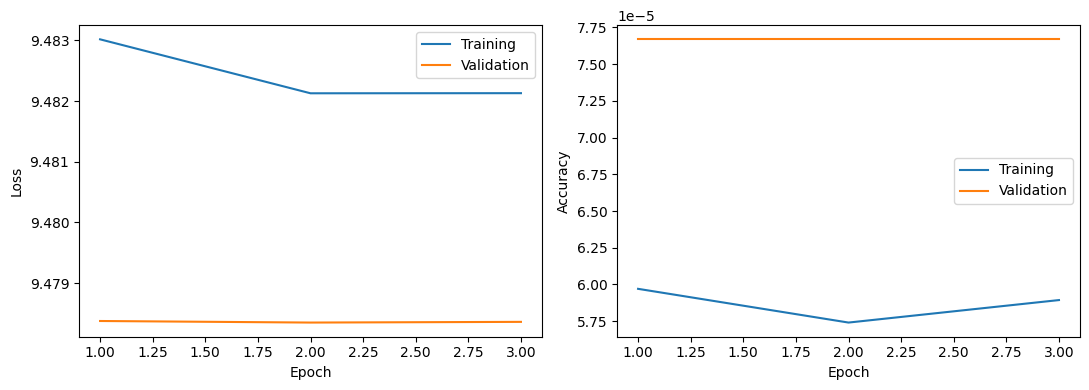


Completed epochs: 3
Best validation accuracy: 0.01% (epoch 1)
Average fit + validation: 5.4 min/epoch
Saved experiment: /content/drive/MyDrive/DIT5411/runs/cnn_small_validation_v1
This is validation-stage training; it is not final test accuracy.
Rerun this file to resume. An interrupted epoch restarts from its beginning.


In [ ]:
"""Run in the user's existing Colab: %run /content/train_dit5411.py

First experiment: small CNN, 3 epochs, 200 augmented training views per class
per epoch. Validation comes from original training images BEFORE augmentation.
The assignment test set is not read. Final refitting on all original training
images and test evaluation are later, separate steps.
"""

from pathlib import Path
import csv
import hashlib
import json
import math
import shutil
import time

import numpy as np


def validation_partition(labels, num_classes, seed=42):
    """Hold out about 10% of each class, using disjoint original-image indices."""
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    assert labels.ndim == 1
    assert np.issubdtype(labels.dtype, np.integer)
    assert labels.min() >= 0 and labels.max() < num_classes
    order = np.argsort(labels, kind="stable")
    counts = np.bincount(labels, minlength=num_classes)
    assert (counts >= 2).all(), "Every class needs at least two original images"
    train_groups, val_groups = [], []
    offset = 0
    for count in counts:
        indices = order[offset:offset + count].copy()
        rng.shuffle(indices)
        n_val = max(1, int(count) // 10)
        val_groups.append(indices[:n_val])
        train_groups.append(indices[n_val:])
        offset += int(count)
    val_indices = np.sort(np.concatenate(val_groups)).astype(np.int32)
    assert len(val_indices) + sum(map(len, train_groups)) == len(labels)
    return train_groups, val_indices


def epoch_plan(groups, views_per_class, seed):
    """Use every original at least once; balance to exactly N views/class."""
    rng = np.random.default_rng(seed)
    blocks = []
    for group in groups:
        assert 0 < len(group) <= views_per_class
        q, r = divmod(views_per_class, len(group))
        block = np.concatenate([
            np.tile(group, q), rng.permutation(group)[:r]
        ])
        blocks.append(block)
    plan = np.concatenate(blocks).astype(np.int32)
    rng.shuffle(plan)
    return plan


def atomic_json(destination, payload):
    destination = Path(destination)
    partial = destination.with_name(destination.name + ".partial")
    partial.write_text(json.dumps(payload, ensure_ascii=False, indent=2),
                       encoding="utf-8")
    partial.replace(destination)


def local_training_arrays(local_dir, cache_dir, expected_count, digest):
    """Unpack one shard at a time to a uint8 disk-backed array (~2 GB)."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    x_path = cache_dir / "train_images.npy"
    y_path = cache_dir / "train_labels.npy"
    ready_path = cache_dir / "ready.json"
    cache_key = {"manifest_sha256": digest, "count": expected_count,
                 "size": 64, "format": "uint8_grayscale_v1"}
    if ready_path.exists() and x_path.exists() and y_path.exists():
        assert json.loads(ready_path.read_text()) == cache_key
        x = np.load(x_path, mmap_mode="r")
        y = np.load(y_path, mmap_mode="r")
        assert x.shape == (expected_count, 64, 64, 1)
        assert x.dtype == np.uint8 and y.shape == (expected_count,)
        return x, y

    paths = sorted(local_dir.glob("train_*.npz"))
    assert len(paths) == 64, "Expected 64 local training shards"
    x = np.lib.format.open_memmap(x_path, mode="w+", dtype=np.uint8,
                                 shape=(expected_count, 64, 64, 1))
    y = np.lib.format.open_memmap(y_path, mode="w+", dtype=np.int32,
                                 shape=(expected_count,))
    offset = 0
    for i, path in enumerate(paths):
        with np.load(path, allow_pickle=False) as data:
            batch_x, batch_y = data["images"], data["labels"]
            n = len(batch_y)
            assert batch_x.shape == (n, 64, 64, 1)
            assert batch_x.dtype == np.uint8
            assert offset + n <= expected_count
            x[offset:offset + n] = batch_x
            y[offset:offset + n] = batch_y
            offset += n
        if (i + 1) % 8 == 0 or i + 1 == len(paths):
            print(f"Unpacking training shards: {i + 1}/{len(paths)}", flush=True)
    assert offset == expected_count
    x.flush()
    y.flush()
    del x, y
    atomic_json(ready_path, cache_key)
    return np.load(x_path, mmap_mode="r"), np.load(y_path, mmap_mode="r")


def completed_records(run_dir, config_hash):
    records = []
    for path in sorted(run_dir.glob("epoch_*.json")):
        record = json.loads(path.read_text())
        assert record["config_hash"] == config_hash, "Checkpoint config mismatch"
        if (run_dir / record["model_file"]).is_file():
            records.append(record)
    for expected, record in enumerate(records, start=1):
        assert record["epoch"] == expected, "Missing an intermediate checkpoint"
    return records


def main():
    import tensorflow as tf
    from tensorflow.keras import layers, mixed_precision
    import matplotlib.pyplot as plt

    PROJECT = Path("/content/drive/MyDrive/DIT5411")
    LOCAL = Path("/content/images_64")
    RUN = PROJECT / "runs" / "cnn_small_validation_v1"
    CACHE = Path("/content/dit5411_cache")
    EPOCHS = 3  # To continue the SAME experiment later, change only this to 6.
    BATCH_SIZE = 128
    NUM_CLASSES = 13065
    VIEWS = 200
    SEED = 42

    assert EPOCHS >= 1
    assert tf.config.list_physical_devices("GPU"), "Connect a GPU first"
    assert (PROJECT / "split_manifest.csv").is_file(), "Mount Google Drive first"
    source = PROJECT / "images_64"
    assert (source / "summary.json").is_file(), "Image backup is incomplete"
    LOCAL.mkdir(parents=True, exist_ok=True)
    # Only restore training shards; the test set is not needed for this stage.
    paths = sorted(source.glob("train_*.npz"))
    assert len(paths) == 64
    for path in paths:
        destination = LOCAL / path.name
        if not destination.exists() or destination.stat().st_size != path.stat().st_size:
            print("Copying", path.name, flush=True)
            partial = destination.with_name(destination.name + ".partial")
            shutil.copyfile(path, partial)
            partial.replace(destination)

    digest = hashlib.sha256((PROJECT / "split_manifest.csv").read_bytes()).hexdigest()
    source_config = json.loads((source / "config.json").read_text())
    assert source_config["manifest_sha256"] == digest
    assert source_config["image_size"] == 64
    summary = json.loads((source / "summary.json").read_text())
    assert summary["train"]["images"] == 521860

    tf.keras.backend.clear_session()
    mixed_precision.set_global_policy("mixed_float16")
    tf.keras.utils.set_random_seed(SEED)
    x, y = local_training_arrays(LOCAL, CACHE, 521860, digest)
    train_groups, val_indices = validation_partition(y, NUM_CLASSES, SEED)
    train_originals = sum(map(len, train_groups))
    views_per_epoch = NUM_CLASSES * VIEWS
    steps = math.ceil(views_per_epoch / BATCH_SIZE)
    val_steps = math.ceil(len(val_indices) / BATCH_SIZE)
    print(f"Classes: {NUM_CLASSES}")
    print(f"Training originals after validation holdout: {train_originals:,}")
    print(f"Validation originals (no augmentation): {len(val_indices):,}")
    print(f"Augmented views per epoch: {views_per_epoch:,} ({VIEWS}/class)")
    print(f"Batches per epoch: {steps:,} train + {val_steps:,} validation")
    print("Assignment test images are reserved for later evaluation.", flush=True)

    config = {
        "experiment": "cnn_small_validation_v1", "manifest_sha256": digest,
        "image_size": 64, "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE, "views_per_class_per_epoch": VIEWS,
        "validation": "per_class_max_1_floor_n_div_10_seeded_originals",
        "seed": SEED, "precision": "mixed_float16",
        "tensorflow": tf.__version__,
        "architecture": "conv32_pool_conv64_pool_flatten_dense128_dropout03_softmax",
        "augmentation": {"rotation_factor": 0.025, "translation": 0.05,
                         "zoom": 0.1, "fill_mode": "nearest"},
        "optimizer": "Adam", "learning_rate": 0.001,
    }
    config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
    RUN.mkdir(parents=True, exist_ok=True)
    config_file = RUN / "config.json"
    if config_file.exists():
        assert json.loads(config_file.read_text()) == config, (
            "Settings changed. Use a new run directory for a new experiment."
        )
    else:
        atomic_json(config_file, config)
    #shutil.copyfile(Path(__file__), RUN / "train_dit5411.py")

    # Save the exact original-image partition before any augmentation.
    partition_path = RUN / "validation_indices.npz"
    if partition_path.exists():
        with np.load(partition_path, allow_pickle=False) as saved:
            assert np.array_equal(saved["indices"], val_indices)
    else:
        temporary = CACHE / "validation_indices.npz"
        np.savez_compressed(temporary, indices=val_indices)
        shutil.copyfile(temporary, partition_path)
    with (RUN / "class_counts.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["label", "train_originals", "validation_originals",
                         "augmented_views_per_epoch"])
        counts = np.bincount(y, minlength=NUM_CLASSES)
        for label, group in enumerate(train_groups):
            writer.writerow([label, len(group), int(counts[label]) - len(group), VIEWS])

    def make_dataset(indices):
        # Disk-backed arrays keep the full float32 dataset out of RAM/GPU memory.
        # The immutable epoch indices also make repeated iterator creation safe.
        def batches():
            for start in range(0, len(indices), BATCH_SIZE):
                selected = indices[start:start + BATCH_SIZE]
                yield np.asarray(x[selected]), np.asarray(y[selected], dtype=np.int32)
        ds = tf.data.Dataset.from_generator(
            batches,
            output_signature=(
                tf.TensorSpec((None, 64, 64, 1), tf.uint8),
                tf.TensorSpec((None,), tf.int32),
            ),
        )
        ds = ds.apply(tf.data.experimental.assert_cardinality(
            math.ceil(len(indices) / BATCH_SIZE)))
        return ds.prefetch(2)

    records = completed_records(RUN, config_hash)
    start_epoch = len(records)
    if records:
        checkpoint = RUN / records[-1]["model_file"]
        print(f"Resuming after epoch {start_epoch}: {checkpoint.name}", flush=True)
        model = tf.keras.models.load_model(checkpoint)
    else:
        model = tf.keras.Sequential([
            layers.Input(shape=(64, 64, 1)),
            layers.Rescaling(1.0 / 255),
            layers.RandomRotation(0.025, fill_mode="nearest", seed=SEED),
            layers.RandomTranslation(0.05, 0.05, fill_mode="nearest", seed=SEED + 1),
            layers.RandomZoom(0.1, fill_mode="nearest", seed=SEED + 2),
            layers.Conv2D(32, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
        ])
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"],
            jit_compile=False,
        )
        with (RUN / "model_summary.txt").open("w") as f:
            model.summary(print_fn=lambda line, **kwargs: f.write(line + "\n"))
    model.summary()
    validation = make_dataset(val_indices)

    # Train one epoch at a time so epoch order is reproducible across restarts.
    # Only a completed model + matching JSON record counts as a committed epoch.
    for epoch in range(start_epoch, EPOCHS):
        plan = epoch_plan(train_groups, VIEWS, SEED + 1000 + epoch)
        assert np.all(np.bincount(y[plan], minlength=NUM_CLASSES) == VIEWS)
        started = time.perf_counter()
        result = model.fit(
            make_dataset(plan), validation_data=validation,
            initial_epoch=epoch, epochs=epoch + 1,
            steps_per_epoch=steps, validation_steps=val_steps, verbose=1,
            callbacks=[tf.keras.callbacks.TerminateOnNaN()],
        )
        metrics = {key: float(value[-1]) for key, value in result.history.items()}
        assert all(np.isfinite(value) for value in metrics.values()), (
            "Non-finite training metrics. The previous checkpoint is preserved."
        )
        assert "val_accuracy" in metrics
        elapsed = time.perf_counter() - started
        filename = f"epoch_{epoch + 1:03d}.keras"
        local_model = CACHE / filename
        model.save(local_model)  # Full model, including optimizer state.
        partial = RUN / (filename + ".partial")
        shutil.copyfile(local_model, partial)
        assert partial.stat().st_size == local_model.stat().st_size
        partial.replace(RUN / filename)
        local_model.unlink()
        record = {"epoch": epoch + 1, "config_hash": config_hash,
                  "model_file": filename, "fit_seconds": elapsed, **metrics}
        atomic_json(RUN / f"epoch_{epoch + 1:03d}.json", record)
        records.append(record)
        best = max(records, key=lambda row: row["val_accuracy"])
        atomic_json(RUN / "best.json", best)
        print(f"Saved epoch {epoch + 1} to Drive. "
              f"Fit + validation: {elapsed / 60:.1f} min. "
              f"Validation accuracy: {metrics['val_accuracy']:.2%}", flush=True)
        del plan

    with (RUN / "history.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)
    best = max(records, key=lambda row: row["val_accuracy"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = [r["epoch"] for r in records]
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, [r[metric] for r in records], label="Training")
        ax.plot(epochs, [r["val_" + metric] for r in records], label="Validation")
        ax.set(xlabel="Epoch", ylabel=metric.title())
        ax.legend()
    fig.tight_layout()
    fig.savefig(RUN / "learning_curves.png", dpi=150)
    plt.show()
    print(f"\nCompleted epochs: {len(records)}")
    print(f"Best validation accuracy: {best['val_accuracy']:.2%} "
          f"(epoch {best['epoch']})")
    print(f"Average fit + validation: "
          f"{np.mean([r['fit_seconds'] for r in records]) / 60:.1f} min/epoch")
    print(f"Saved experiment: {RUN}")
    print("This is validation-stage training; it is not final test accuracy.")
    print("Rerun this file to resume. An interrupted epoch restarts from its beginning.")


if __name__ == "__main__":
    main()


## Historical Diagnostic: Inspect the Initial Model's Dense Layer

Inspect input images and intermediate outputs from the initial model. The 128-unit Dense layer produced all-zero outputs on the checked samples.


圖片形狀： (128, 64, 64, 1)
像素最小／最大： 0 255
平均像素值： 245.78
檢查樣本包含類別數： 17


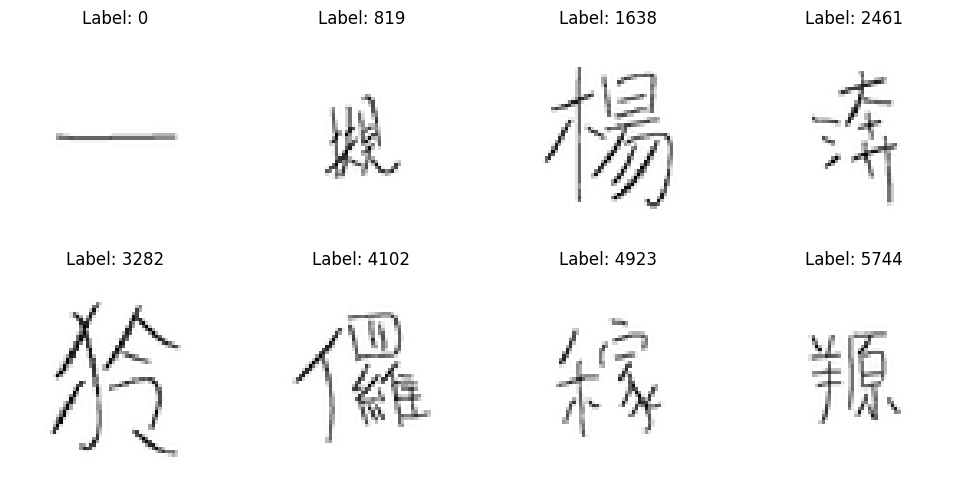


Dense 128 正數輸出比例： 0.0000%
Dense 128 輸出最小／最大： 0.0 0.0
模型預測咗幾多種字： 1
最高預測機率平均值： 8.584465103922412e-05
頭 16 個預測標籤： [1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922, 1922]
頭 16 個真實標籤： [0, 0, 0, 0, 0, 0, 0, 0, 819, 819, 819, 819, 819, 819, 819, 819]


In [ ]:
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 從不同分片抽圖，避免只檢查相近幾個類別
paths = sorted(Path("/content/images_64").glob("train_*.npz"))
image_batches, label_batches = [], []

for path in paths[::4]:
    with np.load(path, allow_pickle=False) as data:
        image_batches.append(data["images"][:8].copy())
        label_batches.append(data["labels"][:8].copy())

x_check = np.concatenate(image_batches)
y_check = np.concatenate(label_batches)

print("圖片形狀：", x_check.shape)
print("像素最小／最大：", x_check.min(), x_check.max())
print("平均像素值：", round(float(x_check.mean()), 2))
print("檢查樣本包含類別數：", len(np.unique(y_check)))

# 顯示不同分片嘅圖片，確認文字清楚可見
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, index in zip(axes.flat, range(0, 64, 8)):
    ax.imshow(x_check[index, :, :, 0],
              cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {y_check[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# 讀取第三個 epoch，檢查中間層
checkpoint = Path(
    "/content/drive/MyDrive/DIT5411/runs/"
    "cnn_small_validation_v1/epoch_003.keras"
)
diagnostic_model = tf.keras.models.load_model(
    checkpoint, compile=False
)

# 逐層計算，檢查 Dense 128 有冇失活
values = tf.convert_to_tensor(x_check)
hidden = None

for layer in diagnostic_model.layers:
    values = layer(values, training=False)

    if isinstance(layer, tf.keras.layers.Dense) and layer.units == 128:
        hidden = values.numpy()

probabilities = values.numpy()
predictions = probabilities.argmax(axis=1)

assert hidden is not None, "搵唔到 Dense 128 層"

print("\nDense 128 正數輸出比例：",
      f"{100 * np.mean(hidden > 0):.4f}%")
print("Dense 128 輸出最小／最大：",
      float(hidden.min()), float(hidden.max()))
print("模型預測咗幾多種字：", len(np.unique(predictions)))
print("最高預測機率平均值：",
      float(probabilities.max(axis=1).mean()))
print("頭 16 個預測標籤：", predictions[:16].tolist())
print("頭 16 個真實標籤：", y_check[:16].tolist())

## Preliminary Learning Check: Corrected Model on 16 Classes

Use 16 character classes and 256 training images to check whether the corrected model can learn. The reported 97.66% is small-sample training accuracy, not held-out test accuracy. These diagnostic weights are not used for the final models.


In [ ]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, mixed_precision

tf.keras.backend.clear_session()
mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(42)

# 重用已解包嘅資料
cache = Path("/content/dit5411_cache")
project = Path("/content/drive/MyDrive/DIT5411")

x = np.load(cache / "train_images.npy", mmap_mode="r")
y = np.load(cache / "train_labels.npy", mmap_mode="r")

# 避開之前劃出嘅 validation 圖片
partition = (
    project / "runs/cnn_small_validation_v1/validation_indices.npz"
)
with np.load(partition, allow_pickle=False) as saved:
    val_indices = saved["indices"].copy()

available = np.ones(len(y), dtype=bool)
available[val_indices] = False

counts = np.bincount(y[available], minlength=13065)
eligible = np.flatnonzero(counts >= 16)

# 揀分布喺不同位置嘅 16 個字
selected_classes = eligible[
    np.linspace(0, len(eligible) - 1, 16, dtype=int)
]

rng = np.random.default_rng(42)
indices = np.concatenate([
    rng.choice(
        np.flatnonzero((y == label) & available),
        size=16,
        replace=False
    )
    for label in selected_classes
])
rng.shuffle(indices)

small_x = np.asarray(x[indices]).copy()
small_y = np.asarray(y[indices], dtype=np.int32)

print("小測試字數：", len(selected_classes))
print("小測試圖片：", len(small_y))

# 保留 13,065 個輸出，測試正式模型嘅結構
check_model = tf.keras.Sequential([
    layers.Input(shape=(64, 64, 1)),

    # 白底 -> 0，黑字 -> 1
    layers.Rescaling(-1.0 / 255, offset=1.0, dtype="float32"),

    layers.RandomRotation(
        0.025, fill_mode="constant", fill_value=0
    ),
    layers.RandomTranslation(
        0.05, 0.05, fill_mode="constant", fill_value=0
    ),
    layers.RandomZoom(
        0.1, fill_mode="constant", fill_value=0
    ),

    layers.Conv2D(
        32, 3, padding="same", kernel_initializer="he_normal"
    ),
    layers.LeakyReLU(negative_slope=0.1),
    layers.MaxPooling2D(),

    layers.Conv2D(
        64, 3, padding="same", kernel_initializer="he_normal"
    ),
    layers.LeakyReLU(negative_slope=0.1),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, kernel_initializer="he_normal"),
    layers.LeakyReLU(negative_slope=0.1, name="features"),
    layers.Dropout(0.2),

    layers.Dense(13065, activation="softmax", dtype="float32")
])

check_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

# 小資料重複練習，檢查模型有冇學習能力
dataset = (
    tf.data.Dataset.from_tensor_slices((small_x, small_y))
    .shuffle(len(small_y), seed=42)
    .batch(64)
    .prefetch(2)
)

class StopWhenLearned(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (logs or {}).get("accuracy", 0) >= 0.95:
            self.model.stop_training = True

check_model.fit(
    dataset,
    epochs=80,
    callbacks=[
        StopWhenLearned(),
        tf.keras.callbacks.TerminateOnNaN()
    ],
    verbose=2
)

loss, accuracy = check_model.evaluate(
    small_x, small_y, batch_size=64, verbose=0
)

probabilities = check_model.predict(
    small_x, batch_size=64, verbose=0
)
predictions = probabilities.argmax(axis=1)

result = {
    "purpose": "small_training_set_learning_check",
    "classes": 16,
    "images": len(small_y),
    "training_accuracy": float(accuracy),
    "loss": float(loss),
    "predicted_class_count": int(len(np.unique(predictions)))
}

(project / "learning_check_v2.json").write_text(
    json.dumps(result, indent=2)
)

print(f"\n小測試訓練準確率：{accuracy:.2%}")
print(f"小測試 loss：{loss:.4f}")
print("預測類別數：", len(np.unique(predictions)))
print("注意：呢個係訓練資料學習檢查，唔係驗證或測試準確率。")

小測試字數： 16
小測試圖片： 256
Epoch 1/80
4/4 - 4s - 1s/step - accuracy: 0.0156 - loss: 9.3900
Epoch 2/80
4/4 - 0s - 95ms/step - accuracy: 0.0859 - loss: 8.9390
Epoch 3/80
4/4 - 0s - 18ms/step - accuracy: 0.0820 - loss: 7.9494
Epoch 4/80
4/4 - 0s - 33ms/step - accuracy: 0.0820 - loss: 6.2635
Epoch 5/80
4/4 - 0s - 36ms/step - accuracy: 0.1016 - loss: 4.5865
Epoch 6/80
4/4 - 0s - 16ms/step - accuracy: 0.0703 - loss: 3.5402
Epoch 7/80
4/4 - 0s - 15ms/step - accuracy: 0.1055 - loss: 3.0447
Epoch 8/80
4/4 - 0s - 33ms/step - accuracy: 0.1562 - loss: 2.8442
Epoch 9/80
4/4 - 0s - 13ms/step - accuracy: 0.0781 - loss: 3.0846
Epoch 10/80
4/4 - 0s - 13ms/step - accuracy: 0.1445 - loss: 2.8673
Epoch 11/80
4/4 - 0s - 13ms/step - accuracy: 0.1562 - loss: 2.6746
Epoch 12/80
4/4 - 0s - 13ms/step - accuracy: 0.1797 - loss: 2.6709
Epoch 13/80
4/4 - 0s - 13ms/step - accuracy: 0.2422 - loss: 2.5498
Epoch 14/80
4/4 - 0s - 13ms/step - accuracy: 0.2305 - loss: 2.4890
Epoch 15/80
4/4 - 0s - 13ms/step - accuracy: 0.2812 

## Model 2: Corrected Simple CNN Validation Training

Use two convolutional blocks and save results in `cnn_small_validation_v2`. This cell defines helper functions needed by the other validation-training cells and prepares the local training cache.


Copying train_000.npz
Copying train_001.npz
Copying train_002.npz
Copying train_003.npz
Copying train_004.npz
Copying train_005.npz
Copying train_006.npz
Copying train_007.npz
Copying train_008.npz
Copying train_009.npz
Copying train_010.npz
Copying train_011.npz
Copying train_012.npz
Copying train_013.npz
Copying train_014.npz
Copying train_015.npz
Copying train_016.npz
Copying train_017.npz
Copying train_018.npz
Copying train_019.npz
Copying train_020.npz
Copying train_021.npz
Copying train_022.npz
Copying train_023.npz
Copying train_024.npz
Copying train_025.npz
Copying train_026.npz
Copying train_027.npz
Copying train_028.npz
Copying train_029.npz
Copying train_030.npz
Copying train_031.npz
Copying train_032.npz
Copying train_033.npz
Copying train_034.npz
Copying train_035.npz
Copying train_036.npz
Copying train_037.npz
Copying train_038.npz
Copying train_039.npz
Copying train_040.npz
Copying train_041.npz
Copying train_042.npz
Copying train_043.npz
Copying train_044.npz
Copying tr

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (LeakyReLU)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,801,481 (14.50 MB)

 Trainable params: 3,801,481 (14.50 MB)

 Non-trainable params: 0 (0.00 B)

20415/20415 ━━━━━━━━━━━━━━━━━━━━ 382s 18ms/step - accuracy: 0.4076 - loss: 3.2423 - val_accuracy: 0.7195 - val_loss: 1.0640

Saved epoch 1 to Drive. Fit + validation: 6.4 min. Validation accuracy: 71.95%
Epoch 2/2
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 368s 18ms/step - accuracy: 0.7272 - loss: 1.0449 - val_accuracy: 0.7646 - val_loss: 0.8922

Saved epoch 2 to Drive. Fit + validation: 6.1 min. Validation accuracy: 76.46%
Epoch 3/3
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 368s 18ms/step - accuracy: 0.7965 - loss: 0.7459 - val_accuracy: 0.7700 - val_loss: 0.8948

Saved epoch 3 to Drive. Fit + validation: 6.1 min. Validation accuracy: 77.00%


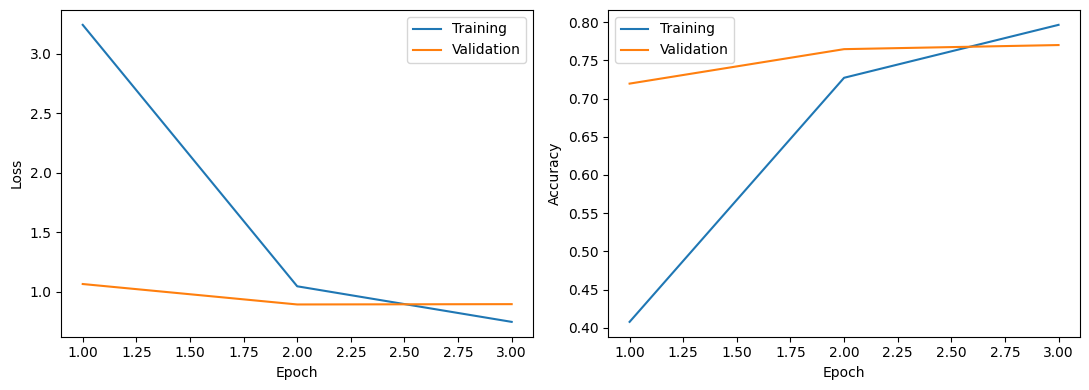


Completed epochs: 3
Best validation accuracy: 77.00% (epoch 3)
Average fit + validation: 6.2 min/epoch
Saved experiment: /content/drive/MyDrive/DIT5411/runs/cnn_small_validation_v2
以上係 validation 結果，未係最終測試準確率。
中斷後重跑呢格，會由最後完成嘅 epoch 繼續。


In [3]:
from pathlib import Path
import csv
import hashlib
import json
import math
import shutil
import time

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, mixed_precision


# ===== 資料分組 =====
def validation_partition(labels, num_classes, seed=42):
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)

    assert labels.ndim == 1
    assert np.issubdtype(labels.dtype, np.integer)
    assert labels.min() >= 0 and labels.max() < num_classes

    order = np.argsort(labels, kind="stable")
    counts = np.bincount(labels, minlength=num_classes)
    assert (counts >= 2).all()

    train_groups = []
    val_groups = []
    offset = 0

    for count in counts:
        indices = order[offset:offset + count].copy()
        rng.shuffle(indices)

        n_val = max(1, int(count) // 10)
        val_groups.append(indices[:n_val])
        train_groups.append(indices[n_val:])
        offset += int(count)

    val_indices = np.sort(
        np.concatenate(val_groups)
    ).astype(np.int32)

    assert (
        len(val_indices) + sum(map(len, train_groups))
        == len(labels)
    )

    return train_groups, val_indices


# ===== 每類每個 epoch 安排 200 個增強輸入 =====
def epoch_plan(groups, views_per_class, seed):
    rng = np.random.default_rng(seed)
    blocks = []

    for group in groups:
        assert 0 < len(group) <= views_per_class

        q, r = divmod(views_per_class, len(group))
        block = np.concatenate([
            np.tile(group, q),
            rng.permutation(group)[:r]
        ])
        blocks.append(block)

    plan = np.concatenate(blocks).astype(np.int32)
    rng.shuffle(plan)
    return plan


# ===== 安全保存 JSON =====
def atomic_json(destination, payload):
    destination = Path(destination)
    partial = destination.with_name(
        destination.name + ".partial"
    )

    partial.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    partial.replace(destination)


# ===== 準備本機圖片陣列，已完成就直接重用 =====
def local_training_arrays(
    local_dir, cache_dir, expected_count, digest
):
    cache_dir.mkdir(parents=True, exist_ok=True)

    x_path = cache_dir / "train_images.npy"
    y_path = cache_dir / "train_labels.npy"
    ready_path = cache_dir / "ready.json"

    cache_key = {
        "manifest_sha256": digest,
        "count": expected_count,
        "size": 64,
        "format": "uint8_grayscale_v1"
    }

    if (
        ready_path.exists()
        and x_path.exists()
        and y_path.exists()
    ):
        assert json.loads(ready_path.read_text()) == cache_key

        x = np.load(x_path, mmap_mode="r")
        y = np.load(y_path, mmap_mode="r")

        assert x.shape == (expected_count, 64, 64, 1)
        assert x.dtype == np.uint8
        assert y.shape == (expected_count,)

        return x, y

    paths = sorted(local_dir.glob("train_*.npz"))
    assert len(paths) == 64, "應該有 64 個訓練分片"

    x = np.lib.format.open_memmap(
        x_path,
        mode="w+",
        dtype=np.uint8,
        shape=(expected_count, 64, 64, 1)
    )

    y = np.lib.format.open_memmap(
        y_path,
        mode="w+",
        dtype=np.int32,
        shape=(expected_count,)
    )

    offset = 0

    for i, path in enumerate(paths):
        with np.load(path, allow_pickle=False) as data:
            batch_x = data["images"]
            batch_y = data["labels"]
            n = len(batch_y)

            assert batch_x.shape == (n, 64, 64, 1)
            assert batch_x.dtype == np.uint8
            assert offset + n <= expected_count

            x[offset:offset + n] = batch_x
            y[offset:offset + n] = batch_y
            offset += n

        if (i + 1) % 8 == 0 or i + 1 == len(paths):
            print(
                f"Unpacking training shards: {i + 1}/{len(paths)}",
                flush=True
            )

    assert offset == expected_count

    x.flush()
    y.flush()
    del x, y

    atomic_json(ready_path, cache_key)

    return (
        np.load(x_path, mmap_mode="r"),
        np.load(y_path, mmap_mode="r")
    )


# ===== 找出已完整保存嘅 epochs =====
def completed_records(run_dir, config_hash):
    records = []

    for path in sorted(run_dir.glob("epoch_*.json")):
        record = json.loads(path.read_text())

        assert record["config_hash"] == config_hash, (
            "Checkpoint 設定不一致"
        )

        if (run_dir / record["model_file"]).is_file():
            records.append(record)

    for expected, record in enumerate(records, start=1):
        assert record["epoch"] == expected, (
            "中間缺少 checkpoint，請先檢查"
        )

    return records


def main():
    PROJECT = Path("/content/drive/MyDrive/DIT5411")
    LOCAL = Path("/content/images_64")
    RUN = PROJECT / "runs" / "cnn_small_validation_v2"
    CACHE = Path("/content/dit5411_cache")

    EPOCHS = 3
    BATCH_SIZE = 128
    NUM_CLASSES = 13065
    VIEWS = 200
    SEED = 42

    assert EPOCHS >= 1
    assert tf.config.list_physical_devices("GPU"), (
        "請先連接 T4 GPU"
    )
    assert (PROJECT / "split_manifest.csv").is_file(), (
        "請先連接 Google Drive"
    )

    source = PROJECT / "images_64"
    assert (source / "summary.json").is_file(), (
        "搵唔到完整圖片備份"
    )

    # 如本機資料消失，從 Drive 還原訓練分片
    LOCAL.mkdir(parents=True, exist_ok=True)
    paths = sorted(source.glob("train_*.npz"))
    assert len(paths) == 64

    for path in paths:
        destination = LOCAL / path.name

        if (
            not destination.exists()
            or destination.stat().st_size != path.stat().st_size
        ):
            print("Copying", path.name, flush=True)

            partial = destination.with_name(
                destination.name + ".partial"
            )
            shutil.copyfile(path, partial)
            partial.replace(destination)

    digest = hashlib.sha256(
        (PROJECT / "split_manifest.csv").read_bytes()
    ).hexdigest()

    source_config = json.loads(
        (source / "config.json").read_text()
    )
    assert source_config["manifest_sha256"] == digest
    assert source_config["image_size"] == 64

    summary = json.loads(
        (source / "summary.json").read_text()
    )
    assert summary["train"]["images"] == 521860

    tf.keras.backend.clear_session()
    mixed_precision.set_global_policy("mixed_float16")
    tf.keras.utils.set_random_seed(SEED)

    x, y = local_training_arrays(
        LOCAL, CACHE, 521860, digest
    )

    train_groups, val_indices = validation_partition(
        y, NUM_CLASSES, SEED
    )

    # 確保同舊版使用完全相同嘅 validation 圖片
    old_partition = (
        PROJECT / "runs" / "cnn_small_validation_v1"
        / "validation_indices.npz"
    )

    if old_partition.exists():
        with np.load(old_partition, allow_pickle=False) as saved:
            assert np.array_equal(
                saved["indices"], val_indices
            ), "Validation 分組改變咗"

    train_originals = sum(map(len, train_groups))
    views_per_epoch = NUM_CLASSES * VIEWS
    steps = math.ceil(views_per_epoch / BATCH_SIZE)
    val_steps = math.ceil(len(val_indices) / BATCH_SIZE)

    print(f"Classes: {NUM_CLASSES}")
    print(
        "Training originals after validation holdout: "
        f"{train_originals:,}"
    )
    print(
        "Validation originals (no augmentation): "
        f"{len(val_indices):,}"
    )
    print(
        f"Augmented views per epoch: {views_per_epoch:,} "
        f"({VIEWS}/class)"
    )
    print(
        f"Batches per epoch: {steps:,} train "
        f"+ {val_steps:,} validation"
    )
    print(
        "Assignment test images are reserved for later evaluation.",
        flush=True
    )

    config = {
        "experiment": "cnn_small_validation_v2",
        "manifest_sha256": digest,
        "image_size": 64,
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
        "views_per_class_per_epoch": VIEWS,
        "validation": "per_class_max_1_floor_n_div_10_seeded_originals",
        "seed": SEED,
        "precision": "mixed_float16",
        "tensorflow": tf.__version__,
        "architecture": (
            "conv32_leaky_pool_conv64_leaky_pool_"
            "flatten_dense128_leaky_dropout02_softmax"
        ),
        "augmentation": {
            "rotation_factor": 0.025,
            "translation": 0.05,
            "zoom": 0.1,
            "fill_mode": "constant",
            "fill_value": 0
        },
        "optimizer": "Adam",
        "learning_rate": 0.0003,
        "clipnorm": 1.0,
        "input_transform": "1_minus_pixel_div_255_float32",
        "negative_slope": 0.1,
        "kernel_initializer": "he_normal"
    }

    config_hash = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()

    RUN.mkdir(parents=True, exist_ok=True)
    config_file = RUN / "config.json"

    if config_file.exists():
        assert json.loads(config_file.read_text()) == config, (
            "設定已改變，唔可以直接使用呢個實驗嘅 checkpoint"
        )
    else:
        atomic_json(config_file, config)

    # 保存 validation 分組
    partition_path = RUN / "validation_indices.npz"

    if partition_path.exists():
        with np.load(partition_path, allow_pickle=False) as saved:
            assert np.array_equal(
                saved["indices"], val_indices
            )
    else:
        temporary = CACHE / "validation_indices.npz"
        np.savez_compressed(temporary, indices=val_indices)
        shutil.copyfile(temporary, partition_path)

    # 保存每類原圖及增強輸入數目
    with (RUN / "class_counts.csv").open(
        "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.writer(f)
        writer.writerow([
            "label",
            "train_originals",
            "validation_originals",
            "augmented_views_per_epoch"
        ])

        counts = np.bincount(y, minlength=NUM_CLASSES)

        for label, group in enumerate(train_groups):
            writer.writerow([
                label,
                len(group),
                int(counts[label]) - len(group),
                VIEWS
            ])

    # 分批讀圖，避免將整個 float32 資料集放入記憶體
    def make_dataset(indices):
        def batches():
            for start in range(0, len(indices), BATCH_SIZE):
                selected = indices[start:start + BATCH_SIZE]

                yield (
                    np.asarray(x[selected]),
                    np.asarray(y[selected], dtype=np.int32)
                )

        ds = tf.data.Dataset.from_generator(
            batches,
            output_signature=(
                tf.TensorSpec(
                    (None, 64, 64, 1), tf.uint8
                ),
                tf.TensorSpec(
                    (None,), tf.int32
                )
            )
        )

        ds = ds.apply(
            tf.data.experimental.assert_cardinality(
                math.ceil(len(indices) / BATCH_SIZE)
            )
        )

        return ds.prefetch(2)

    records = completed_records(RUN, config_hash)
    start_epoch = len(records)

    if records:
        # 恢復新版已完成嘅訓練
        checkpoint = RUN / records[-1]["model_file"]

        print(
            f"Resuming after epoch {start_epoch}: "
            f"{checkpoint.name}",
            flush=True
        )
        model = tf.keras.models.load_model(checkpoint)

    else:
        # 全新模型：唔使用舊版或小測試嘅權重
        model = tf.keras.Sequential([
            layers.Input(shape=(64, 64, 1)),

            # 白底 -> 0，黑色筆畫 -> 1
            layers.Rescaling(
                -1.0 / 255,
                offset=1.0,
                dtype="float32"
            ),

            layers.RandomRotation(
                0.025,
                fill_mode="constant",
                fill_value=0,
                seed=SEED
            ),
            layers.RandomTranslation(
                0.05,
                0.05,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 1
            ),
            layers.RandomZoom(
                0.1,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 2
            ),

            layers.Conv2D(
                32,
                3,
                padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            layers.Conv2D(
                64,
                3,
                padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            layers.Flatten(),
            layers.Dense(
                128,
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(
                negative_slope=0.1,
                name="features"
            ),
            layers.Dropout(0.2),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax",
                dtype="float32"
            )
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.0003,
                clipnorm=1.0
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
            jit_compile=False
        )

        with (RUN / "model_summary.txt").open("w") as f:
            model.summary(
                print_fn=lambda line, **kwargs: f.write(
                    line + "\n"
                )
            )

    model.summary()
    validation = make_dataset(val_indices)

    # 每完成一個 epoch，保存完整模型及 optimizer 狀態
    for epoch in range(start_epoch, EPOCHS):
        plan = epoch_plan(
            train_groups,
            VIEWS,
            SEED + 1000 + epoch
        )

        assert np.all(
            np.bincount(
                y[plan], minlength=NUM_CLASSES
            ) == VIEWS
        )

        started = time.perf_counter()

        result = model.fit(
            make_dataset(plan),
            validation_data=validation,
            initial_epoch=epoch,
            epochs=epoch + 1,
            steps_per_epoch=steps,
            validation_steps=val_steps,
            verbose=1,
            callbacks=[
                tf.keras.callbacks.TerminateOnNaN()
            ]
        )

        metrics = {
            key: float(value[-1])
            for key, value in result.history.items()
        }

        assert all(
            np.isfinite(value)
            for value in metrics.values()
        ), "出現非有限數值，已保留上一個 checkpoint"

        assert "val_accuracy" in metrics
        elapsed = time.perf_counter() - started

        filename = f"epoch_{epoch + 1:03d}.keras"
        local_model = CACHE / filename

        model.save(local_model)

        partial = RUN / (filename + ".partial")
        shutil.copyfile(local_model, partial)

        assert (
            partial.stat().st_size
            == local_model.stat().st_size
        )

        partial.replace(RUN / filename)
        local_model.unlink()

        record = {
            "epoch": epoch + 1,
            "config_hash": config_hash,
            "model_file": filename,
            "fit_seconds": elapsed,
            **metrics
        }

        atomic_json(
            RUN / f"epoch_{epoch + 1:03d}.json",
            record
        )
        records.append(record)

        best = max(
            records,
            key=lambda row: row["val_accuracy"]
        )
        atomic_json(RUN / "best.json", best)

        print(
            f"\nSaved epoch {epoch + 1} to Drive. "
            f"Fit + validation: {elapsed / 60:.1f} min. "
            f"Validation accuracy: "
            f"{metrics['val_accuracy']:.2%}",
            flush=True
        )

        del plan

    # 保存完整訓練紀錄
    with (RUN / "history.csv").open(
        "w", newline=""
    ) as f:
        writer = csv.DictWriter(
            f, fieldnames=list(records[0])
        )
        writer.writeheader()
        writer.writerows(records)

    # 畫訓練曲線
    best = max(
        records,
        key=lambda row: row["val_accuracy"]
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4)
    )
    epochs = [r["epoch"] for r in records]

    for ax, metric in zip(
        axes, ["loss", "accuracy"]
    ):
        ax.plot(
            epochs,
            [r[metric] for r in records],
            label="Training"
        )
        ax.plot(
            epochs,
            [r["val_" + metric] for r in records],
            label="Validation"
        )
        ax.set(
            xlabel="Epoch",
            ylabel=metric.title()
        )
        ax.legend()

    fig.tight_layout()
    fig.savefig(
        RUN / "learning_curves.png", dpi=150
    )
    plt.show()

    print(f"\nCompleted epochs: {len(records)}")
    print(
        f"Best validation accuracy: "
        f"{best['val_accuracy']:.2%} "
        f"(epoch {best['epoch']})"
    )
    print(
        "Average fit + validation: "
        f"{np.mean([r['fit_seconds'] for r in records]) / 60:.1f} "
        "min/epoch"
    )
    print(f"Saved experiment: {RUN}")
    print("以上係 validation 結果，未係最終測試準確率。")
    print("中斷後重跑呢格，會由最後完成嘅 epoch 繼續。")


main()

## Model 1: ANN Validation Training

Use Flatten, a 256-unit Dense layer, LeakyReLU, Dropout, and a 13,065-unit output layer. Save validation-stage results in `ann_mlp_validation_v1`.

Execute the corrected Simple CNN cell first to define the required helper functions.


In [4]:
# ===== DIT5411 Model 1: Multi-layer ANN =====

from pathlib import Path
import csv
import hashlib
import json
import math
import shutil
import time

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, mixed_precision

PROJECT = Path("/content/drive/MyDrive/DIT5411")
SOURCE = PROJECT / "images_64"
LOCAL = Path("/content/images_64")
CACHE = Path("/content/dit5411_cache")

RUN = PROJECT / "runs" / "ann_mlp_validation_v1"

EPOCHS = 3
BATCH_SIZE = 128
NUM_CLASSES = 13065
VIEWS = 200
SEED = 42

assert tf.config.list_physical_devices("GPU"), "請先連接 T4 GPU"
assert (PROJECT / "split_manifest.csv").is_file()
assert (SOURCE / "summary.json").is_file()

# 確保輔助函數已存在
assert "validation_partition" in globals(), (
    "請先執行新版 v2 CNN 程式格一次"
)
assert "epoch_plan" in globals()
assert "local_training_arrays" in globals()
assert "completed_records" in globals()
assert "atomic_json" in globals()

# 如果執行階段重設，從 Drive 還原訓練分片
LOCAL.mkdir(parents=True, exist_ok=True)

for path in sorted(SOURCE.glob("train_*.npz")):
    destination = LOCAL / path.name

    if (
        not destination.exists()
        or destination.stat().st_size != path.stat().st_size
    ):
        print("Copying", path.name, flush=True)
        partial = destination.with_name(
            destination.name + ".partial"
        )
        shutil.copyfile(path, partial)
        partial.replace(destination)

assert len(list(LOCAL.glob("train_*.npz"))) == 64

digest = hashlib.sha256(
    (PROJECT / "split_manifest.csv").read_bytes()
).hexdigest()

source_config = json.loads(
    (SOURCE / "config.json").read_text()
)

assert source_config["manifest_sha256"] == digest
assert source_config["image_size"] == 64

tf.keras.backend.clear_session()
mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(SEED)

x, y = local_training_arrays(
    LOCAL,
    CACHE,
    521860,
    digest
)

# 使用 CNN v2 已保存的相同 validation 分組
partition_file = (
    PROJECT
    / "runs"
    / "cnn_small_validation_v2"
    / "validation_indices.npz"
)

assert partition_file.is_file(), (
    "搵唔到 CNN v2 validation 分組"
)

with np.load(partition_file, allow_pickle=False) as saved:
    val_indices = saved["indices"].copy()

val_mask = np.zeros(len(y), dtype=bool)
val_mask[val_indices] = True

# 每個類別嘅訓練原圖，排除 validation 圖片
train_groups = [
    np.flatnonzero((y == label) & (~val_mask))
    for label in range(NUM_CLASSES)
]

assert sum(len(group) for group in train_groups) == 469700
assert len(val_indices) == 52160

views_per_epoch = NUM_CLASSES * VIEWS
steps = math.ceil(views_per_epoch / BATCH_SIZE)
val_steps = math.ceil(len(val_indices) / BATCH_SIZE)

print("Model: Multi-layer ANN")
print("Classes:", NUM_CLASSES)
print("Training originals:", sum(map(len, train_groups)))
print("Validation originals:", len(val_indices))
print("Augmented views per epoch:", views_per_epoch)
print("Batches:", steps, "train +", val_steps, "validation")


config = {
    "experiment": "ann_mlp_validation_v1",
    "manifest_sha256": digest,
    "image_size": 64,
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "views_per_class_per_epoch": VIEWS,
    "validation_source": "cnn_small_validation_v2",
    "seed": SEED,
    "precision": "mixed_float16",
    "architecture": (
        "flatten_dense256_leaky_dropout02_softmax"
    ),
    "augmentation": {
        "rotation_factor": 0.025,
        "translation": 0.05,
        "zoom": 0.1,
        "fill_mode": "constant",
        "fill_value": 0
    },
    "optimizer": "Adam",
    "learning_rate": 0.0003,
    "clipnorm": 1.0,
    "input_transform": "1_minus_pixel_div_255_float32"
}

config_hash = hashlib.sha256(
    json.dumps(config, sort_keys=True).encode()
).hexdigest()

RUN.mkdir(parents=True, exist_ok=True)

config_file = RUN / "config.json"

if config_file.exists():
    assert json.loads(config_file.read_text()) == config
else:
    atomic_json(config_file, config)


def make_dataset(indices):
    def batches():
        for start in range(0, len(indices), BATCH_SIZE):
            selected = indices[start:start + BATCH_SIZE]

            yield (
                np.asarray(x[selected]),
                np.asarray(y[selected], dtype=np.int32)
            )

    dataset = tf.data.Dataset.from_generator(
        batches,
        output_signature=(
            tf.TensorSpec(
                shape=(None, 64, 64, 1),
                dtype=tf.uint8
            ),
            tf.TensorSpec(
                shape=(None,),
                dtype=tf.int32
            )
        )
    )

    dataset = dataset.apply(
        tf.data.experimental.assert_cardinality(
            math.ceil(len(indices) / BATCH_SIZE)
        )
    )

    return dataset.prefetch(2)


records = completed_records(RUN, config_hash)
start_epoch = len(records)

if records:
    checkpoint = RUN / records[-1]["model_file"]
    print("Resume from:", checkpoint.name)
    model = tf.keras.models.load_model(checkpoint)

else:
    # 多層 ANN：沒有卷積層
    model = tf.keras.Sequential([
        layers.Input(shape=(64, 64, 1)),

        # 白底變 0，黑色筆畫變 1
        layers.Rescaling(
            -1.0 / 255,
            offset=1.0,
            dtype="float32"
        ),

        layers.RandomRotation(
            0.025,
            fill_mode="constant",
            fill_value=0,
            seed=SEED
        ),
        layers.RandomTranslation(
            0.05,
            0.05,
            fill_mode="constant",
            fill_value=0,
            seed=SEED + 1
        ),
        layers.RandomZoom(
            0.1,
            fill_mode="constant",
            fill_value=0,
            seed=SEED + 2
        ),

        layers.Flatten(),

        layers.Dense(
            256,
            kernel_initializer="he_normal"
        ),
        layers.LeakyReLU(negative_slope=0.1),

        layers.Dropout(0.2),

        layers.Dense(
            NUM_CLASSES,
            activation="softmax",
            dtype="float32"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0003,
            clipnorm=1.0
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False
    )

model.summary()

validation_data = make_dataset(val_indices)

for epoch in range(start_epoch, EPOCHS):
    plan = epoch_plan(
        train_groups,
        VIEWS,
        SEED + 2000 + epoch
    )

    assert np.all(
        np.bincount(
            y[plan],
            minlength=NUM_CLASSES
        ) == VIEWS
    )

    started = time.perf_counter()

    result = model.fit(
        make_dataset(plan),
        validation_data=validation_data,
        initial_epoch=epoch,
        epochs=epoch + 1,
        steps_per_epoch=steps,
        validation_steps=val_steps,
        verbose=1,
        callbacks=[
            tf.keras.callbacks.TerminateOnNaN()
        ]
    )

    metrics = {
        key: float(value[-1])
        for key, value in result.history.items()
    }

    elapsed = time.perf_counter() - started
    filename = f"epoch_{epoch + 1:03d}.keras"

    local_model = CACHE / filename
    model.save(local_model)

    partial = RUN / (filename + ".partial")
    shutil.copyfile(local_model, partial)
    partial.replace(RUN / filename)
    local_model.unlink()

    record = {
        "epoch": epoch + 1,
        "config_hash": config_hash,
        "model_file": filename,
        "fit_seconds": elapsed,
        **metrics
    }

    atomic_json(
        RUN / f"epoch_{epoch + 1:03d}.json",
        record
    )

    records.append(record)

    best = max(
        records,
        key=lambda row: row["val_accuracy"]
    )
    atomic_json(RUN / "best.json", best)

    print(
        f"\nSaved ANN epoch {epoch + 1}. "
        f"Time: {elapsed / 60:.1f} min. "
        f"Validation accuracy: "
        f"{metrics['val_accuracy']:.2%}",
        flush=True
    )

    del plan

with (RUN / "history.csv").open(
    "w",
    newline=""
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0])
    )
    writer.writeheader()
    writer.writerows(records)

best = max(
    records,
    key=lambda row: row["val_accuracy"]
)

print("\nANN completed epochs:", len(records))
print(
    f"Best ANN validation accuracy: "
    f"{best['val_accuracy']:.2%}"
)
print("Saved to:", RUN)
print("以上係 validation accuracy，未係最終 test accuracy。")

Model: Multi-layer ANN
Classes: 13065
Training originals: 469700
Validation originals: 52160
Augmented views per epoch: 2613000
Batches: 20415 train + 408 validation


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     3,357,705 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,406,537 (16.81 MB)

 Trainable params: 4,406,537 (16.81 MB)

 Non-trainable params: 0 (0.00 B)

20415/20415 ━━━━━━━━━━━━━━━━━━━━ 249s 12ms/step - accuracy: 0.0432 - loss: 7.0676 - val_accuracy: 0.1718 - val_loss: 5.0396

Saved ANN epoch 1. Time: 4.1 min. Validation accuracy: 17.18%
Epoch 2/2
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 247s 12ms/step - accuracy: 0.1326 - loss: 5.3940 - val_accuracy: 0.2795 - val_loss: 4.0515

Saved ANN epoch 2. Time: 4.1 min. Validation accuracy: 27.95%
Epoch 3/3
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 245s 12ms/step - accuracy: 0.1856 - loss: 4.7923 - val_accuracy: 0.3405 - val_loss: 3.5745

Saved ANN epoch 3. Time: 4.1 min. Validation accuracy: 34.05%

ANN completed epochs: 3
Best ANN validation accuracy: 34.05%
Saved to: /content/drive/MyDrive/DIT5411/runs/ann_mlp_validation_v1
以上係 validation accuracy，未係最終 test accuracy。


## Model 3: Deep CNN Validation Training (Six-Epoch Experiment)

Extend the three-block Deep CNN validation experiment to a total of six epochs. The highest validation accuracy was 92.32% at epoch four.


恢復模型： epoch_003.keras


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (LeakyReLU)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,480,289 (32.35 MB)

 Trainable params: 2,826,761 (10.78 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,653,528 (21.57 MB)

Training originals: 469700
Validation originals: 52160
Augmented views per epoch: 2613000
今次唔會讀取正式 test set。
Epoch 4/4
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 402s 20ms/step - accuracy: 0.9156 - loss: 0.2782 - val_accuracy: 0.9232 - val_loss: 0.2743

Saved deep CNN epoch 4. Time: 6.7 min. Validation accuracy: 92.32%
Epoch 5/5
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 398s 20ms/step - accuracy: 0.9289 - loss: 0.2316 - val_accuracy: 0.9151 - val_loss: 0.3111

Saved deep CNN epoch 5. Time: 6.6 min. Validation accuracy: 91.51%
Epoch 6/6
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 403s 20ms/step - accuracy: 0.9374 - loss: 0.2021 - val_accuracy: 0.9180 - val_loss: 0.3146

Saved deep CNN epoch 6. Time: 6.7 min. Validation accuracy: 91.80%


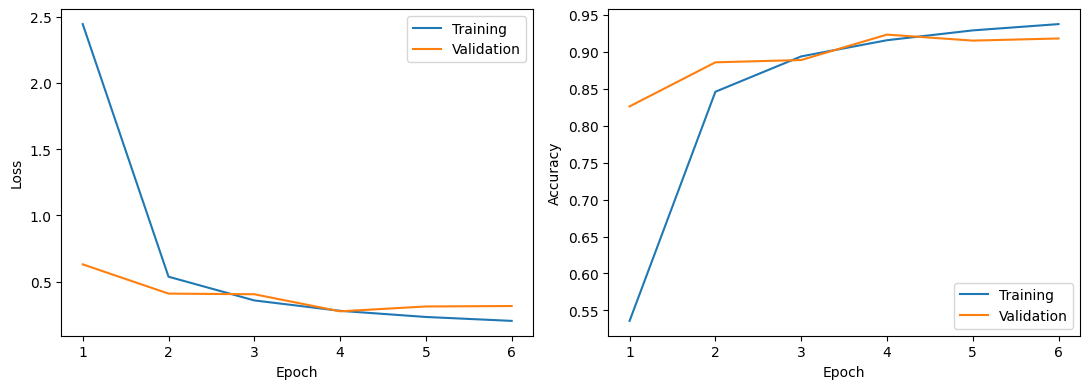


Completed epochs: 6
Best deep CNN validation accuracy: 92.32% (epoch 4)
Saved to: /content/drive/MyDrive/DIT5411/runs/cnn_deep_validation_v1

===== 三個模型比較：Validation =====
ANN: 34.05% (epoch 3)
Simple CNN: 77.00% (epoch 3)
Deep CNN: 92.32% (epoch 4)

以上仍然係 validation，未係最終 test accuracy。


In [6]:
# ===== Model 3：較深 CNN =====

from pathlib import Path
import csv
import hashlib
import json
import math
import shutil
import time

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, mixed_precision


def train_deeper_cnn():
    PROJECT = Path("/content/drive/MyDrive/DIT5411")
    CACHE = Path("/content/dit5411_cache")
    RUN = PROJECT / "runs" / "cnn_deep_validation_v1"

    EPOCHS = 6
    BATCH_SIZE = 128
    NUM_CLASSES = 13065
    VIEWS = 200
    SEED = 42

    assert tf.config.list_physical_devices("GPU"), (
        "請先連接 T4 GPU"
    )
    assert (PROJECT / "split_manifest.csv").is_file(), (
        "請先連接 Google Drive"
    )

    # 沿用之前完整訓練格定義嘅輔助函數
    helpers = [
        "validation_partition",
        "epoch_plan",
        "atomic_json",
        "completed_records"
    ]
    missing = [name for name in helpers if name not in globals()]
    assert not missing, (
        f"缺少輔助函數：{missing}。"
        "如果剛重設執行階段，請先還原新版 v2 訓練格嘅函數。"
    )

    assert (CACHE / "ready.json").is_file(), (
        "本機圖片快取不存在，請先還原訓練資料"
    )

    digest = hashlib.sha256(
        (PROJECT / "split_manifest.csv").read_bytes()
    ).hexdigest()

    cache_config = json.loads(
        (CACHE / "ready.json").read_text()
    )
    assert cache_config["manifest_sha256"] == digest

    # 重用本機磁碟陣列，唔重新下載或解壓
    x = np.load(
        CACHE / "train_images.npy",
        mmap_mode="r"
    )
    y = np.load(
        CACHE / "train_labels.npy",
        mmap_mode="r"
    )

    assert x.shape == (521860, 64, 64, 1)
    assert x.dtype == np.uint8
    assert y.shape == (521860,)

    train_groups, val_indices = validation_partition(
        y, NUM_CLASSES, SEED
    )

    # 確認同簡單 CNN 使用完全相同嘅 validation 圖片
    reference_partition = (
        PROJECT / "runs" / "cnn_small_validation_v2"
        / "validation_indices.npz"
    )
    with np.load(
        reference_partition, allow_pickle=False
    ) as saved:
        assert np.array_equal(
            saved["indices"], val_indices
        ), "Validation 分組不一致"

    assert sum(map(len, train_groups)) == 469700
    assert len(val_indices) == 52160

    tf.keras.backend.clear_session()
    mixed_precision.set_global_policy("mixed_float16")
    tf.keras.utils.set_random_seed(SEED)

    config = {
        "experiment": "cnn_deep_validation_v1",
        "manifest_sha256": digest,
        "tensorflow": tf.__version__,
        "architecture": (
            "conv32_pool_conv64_pool_conv128_pool_"
            "flatten_dense128_dropout02_softmax"
        ),
        "input_size": 64,
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
        "views_per_class_per_epoch": VIEWS,
        "validation_source": "cnn_small_validation_v2",
        "validation_indices_sha256": hashlib.sha256(
            val_indices.tobytes()
        ).hexdigest(),
        "seed": SEED,
        "sampling_seed_base": SEED + 1000,
        "precision": "mixed_float16",
        "input_transform": "1_minus_pixel_div_255_float32",
        "augmentation": {
            "rotation_factor": 0.025,
            "translation": 0.05,
            "zoom": 0.1,
            "fill_mode": "constant",
            "fill_value": 0
        },
        "activation": "LeakyReLU",
        "negative_slope": 0.1,
        "kernel_initializer": "he_normal",
        "dropout": 0.2,
        "optimizer": "Adam",
        "learning_rate": 0.0003,
        "clipnorm": 1.0
    }

    config_hash = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()

    RUN.mkdir(parents=True, exist_ok=True)
    config_file = RUN / "config.json"

    if config_file.exists():
        assert json.loads(config_file.read_text()) == config, (
            "實驗設定改變，請先檢查，唔好覆蓋舊 checkpoint"
        )
    else:
        atomic_json(config_file, config)

    # 保存分組副本
    partition_path = RUN / "validation_indices.npz"
    if partition_path.exists():
        with np.load(
            partition_path, allow_pickle=False
        ) as saved:
            assert np.array_equal(
                saved["indices"], val_indices
            )
    else:
        temporary = CACHE / "deep_validation_indices.npz"
        np.savez_compressed(
            temporary, indices=val_indices
        )
        shutil.copyfile(temporary, partition_path)

    def make_dataset(indices):
        def batches():
            for start in range(
                0, len(indices), BATCH_SIZE
            ):
                selected = indices[
                    start:start + BATCH_SIZE
                ]
                yield (
                    np.asarray(x[selected]),
                    np.asarray(
                        y[selected], dtype=np.int32
                    )
                )

        dataset = tf.data.Dataset.from_generator(
            batches,
            output_signature=(
                tf.TensorSpec(
                    (None, 64, 64, 1), tf.uint8
                ),
                tf.TensorSpec(
                    (None,), tf.int32
                )
            )
        )
        dataset = dataset.apply(
            tf.data.experimental.assert_cardinality(
                math.ceil(
                    len(indices) / BATCH_SIZE
                )
            )
        )
        return dataset.prefetch(2)

    records = completed_records(RUN, config_hash)
    start_epoch = len(records)

    if records:
        checkpoint = RUN / records[-1]["model_file"]
        print("恢復模型：", checkpoint.name)
        model = tf.keras.models.load_model(checkpoint)

    else:
        model = tf.keras.Sequential([
            layers.Input(shape=(64, 64, 1)),

            layers.Rescaling(
                -1.0 / 255,
                offset=1.0,
                dtype="float32"
            ),
            layers.RandomRotation(
                0.025,
                fill_mode="constant",
                fill_value=0,
                seed=SEED
            ),
            layers.RandomTranslation(
                0.05, 0.05,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 1
            ),
            layers.RandomZoom(
                0.1,
                fill_mode="constant",
                fill_value=0,
                seed=SEED + 2
            ),

            # 卷積區塊 1：64×64 -> 32×32
            layers.Conv2D(
                32, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            # 卷積區塊 2：32×32 -> 16×16
            layers.Conv2D(
                64, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            # 卷積區塊 3：16×16 -> 8×8
            layers.Conv2D(
                128, 3, padding="same",
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(negative_slope=0.1),
            layers.MaxPooling2D(),

            layers.Flatten(),
            layers.Dense(
                128,
                kernel_initializer="he_normal"
            ),
            layers.LeakyReLU(
                negative_slope=0.1,
                name="features"
            ),
            layers.Dropout(0.2),

            layers.Dense(
                NUM_CLASSES,
                activation="softmax",
                dtype="float32"
            )
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.0003,
                clipnorm=1.0
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
            jit_compile=False
        )

    model.summary()

    with (RUN / "model_summary.txt").open("w") as f:
        model.summary(
            print_fn=lambda line, **kwargs: f.write(
                line + "\n"
            )
        )

    print("Training originals:", sum(map(len, train_groups)))
    print("Validation originals:", len(val_indices))
    print("Augmented views per epoch:", NUM_CLASSES * VIEWS)
    print("今次唔會讀取正式 test set。")

    steps = math.ceil(
        NUM_CLASSES * VIEWS / BATCH_SIZE
    )
    val_steps = math.ceil(
        len(val_indices) / BATCH_SIZE
    )
    validation_data = make_dataset(val_indices)

    for epoch in range(start_epoch, EPOCHS):
        # 同簡單 CNN 使用相同原圖抽樣次序
        plan = epoch_plan(
            train_groups,
            VIEWS,
            SEED + 1000 + epoch
        )

        assert np.all(
            np.bincount(
                y[plan],
                minlength=NUM_CLASSES
            ) == VIEWS
        )

        started = time.perf_counter()

        result = model.fit(
            make_dataset(plan),
            validation_data=validation_data,
            initial_epoch=epoch,
            epochs=epoch + 1,
            steps_per_epoch=steps,
            validation_steps=val_steps,
            callbacks=[
                tf.keras.callbacks.TerminateOnNaN()
            ],
            verbose=1
        )

        metrics = {
            key: float(value[-1])
            for key, value in result.history.items()
        }
        assert "val_accuracy" in metrics
        assert all(
            np.isfinite(value)
            for value in metrics.values()
        ), "出現非有限數值，停止保存本輪模型"

        elapsed = time.perf_counter() - started

        filename = f"epoch_{epoch + 1:03d}.keras"
        local_model = CACHE / f"deep_{filename}"
        model.save(local_model)

        partial = RUN / (filename + ".partial")
        shutil.copyfile(local_model, partial)

        assert (
            partial.stat().st_size
            == local_model.stat().st_size
        )

        partial.replace(RUN / filename)
        local_model.unlink()

        record = {
            "epoch": epoch + 1,
            "config_hash": config_hash,
            "model_file": filename,
            "fit_seconds": elapsed,
            **metrics
        }

        atomic_json(
            RUN / f"epoch_{epoch + 1:03d}.json",
            record
        )
        records.append(record)

        best = max(
            records,
            key=lambda row: row["val_accuracy"]
        )
        atomic_json(RUN / "best.json", best)

        # 每輪保存累積紀錄
        with (RUN / "history.csv").open(
            "w", newline=""
        ) as f:
            writer = csv.DictWriter(
                f, fieldnames=list(records[0])
            )
            writer.writeheader()
            writer.writerows(records)

        print(
            f"\nSaved deep CNN epoch {epoch + 1}. "
            f"Time: {elapsed / 60:.1f} min. "
            f"Validation accuracy: "
            f"{metrics['val_accuracy']:.2%}",
            flush=True
        )
        del plan

    # 畫圖
    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4)
    )
    epoch_numbers = [r["epoch"] for r in records]

    for ax, metric in zip(
        axes, ["loss", "accuracy"]
    ):
        ax.plot(
            epoch_numbers,
            [r[metric] for r in records],
            label="Training"
        )
        ax.plot(
            epoch_numbers,
            [r["val_" + metric] for r in records],
            label="Validation"
        )
        ax.set(
            xlabel="Epoch",
            ylabel=metric.title()
        )
        ax.legend()

    fig.tight_layout()
    fig.savefig(
        RUN / "learning_curves.png", dpi=150
    )
    plt.show()

    best = max(
        records,
        key=lambda row: row["val_accuracy"]
    )

    print("\nCompleted epochs:", len(records))
    print(
        f"Best deep CNN validation accuracy: "
        f"{best['val_accuracy']:.2%} "
        f"(epoch {best['epoch']})"
    )
    print("Saved to:", RUN)

    # 顯示目前三個模型嘅最佳 validation 結果
    print("\n===== 三個模型比較：Validation =====")
    experiments = [
        ("ANN", "ann_mlp_validation_v1"),
        ("Simple CNN", "cnn_small_validation_v2"),
        ("Deep CNN", "cnn_deep_validation_v1")
    ]

    for name, folder in experiments:
        best_path = PROJECT / "runs" / folder / "best.json"
        if best_path.exists():
            row = json.loads(best_path.read_text())
            print(
                f"{name}: {row['val_accuracy']:.2%} "
                f"(epoch {row['epoch']})"
            )

    print("\n以上仍然係 validation，未係最終 test accuracy。")


train_deeper_cnn()

## Final Training of Three Models and Held-Out Test Evaluation

Select a T4 GPU and mount Google Drive before executing this self-contained cell. It does not depend on helper functions from earlier training cells.

Train ANN for three epochs, Simple CNN for three epochs, and Deep CNN for four epochs using all 521,860 original training images. Each class contributes 200 augmented training views per epoch.

After all training is complete, evaluate the fixed final checkpoints on the 20 test shards. Save results in `MyDrive/DIT5411/final_results/`. The saved output below contains the completed final test results.


In [3]:
# 最後訓練及正式測試：直接將成格貼入 Colab 執行
from pathlib import Path
import csv
import gc
import hashlib
import json
import math
import shutil
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, mixed_precision

PROJECT = Path("/content/drive/MyDrive/DIT5411")
SOURCE = PROJECT / "images_64"
ROOT = PROJECT / "final_results"
CACHE = Path("/content/dit5411_cache")
LOCAL = Path("/content/images_64")
N_CLASSES, BATCH, VIEWS, SEED = 13065, 128, 200, 42
SPECS = [("ANN", "ann", 3), ("Simple CNN", "simple_cnn", 3),
         ("Deep CNN", "deep_cnn", 4)]


def save_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".partial")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2),
                         encoding="utf-8")
    temporary.replace(path)


def copy_saved(source, destination):
    destination = Path(destination)
    partial = destination.with_name(destination.name + ".partial")
    shutil.copyfile(source, partial)
    assert partial.stat().st_size == Path(source).stat().st_size
    partial.replace(destination)


def read_manifest(path):
    labels, splits = [], []
    with path.open(encoding="utf-8", newline="") as f:
        for row in csv.DictReader(f):
            assert row["split"] in ("train", "test")
            labels.append(int(row["label"]))
            splits.append(row["split"] == "train")
    labels = np.asarray(labels, dtype=np.int32)
    is_train = np.asarray(splits, dtype=bool)
    assert len(labels) == 684677
    assert is_train.sum() == 521860
    assert (~is_train).sum() == 162817
    assert labels.min() == 0 and labels.max() == N_CLASSES - 1
    return labels, is_train


def prepare_training(digest, manifest_y, is_train):
    CACHE.mkdir(parents=True, exist_ok=True)
    LOCAL.mkdir(parents=True, exist_ok=True)
    xp, yp = CACHE / "train_images.npy", CACHE / "train_labels.npy"
    ready = CACHE / "ready.json"
    key = {"manifest_sha256": digest, "count": 521860, "size": 64,
           "format": "uint8_grayscale_v1"}
    if not (ready.exists() and xp.exists() and yp.exists()
            and json.loads(ready.read_text()) == key):
        paths = sorted(SOURCE.glob("train_*.npz"))
        assert len(paths) == 64, "需要 64 個訓練分片"
        x = np.lib.format.open_memmap(xp, mode="w+", dtype=np.uint8,
                                     shape=(521860, 64, 64, 1))
        y = np.lib.format.open_memmap(yp, mode="w+", dtype=np.int32,
                                     shape=(521860,))
        expected_ids = np.flatnonzero(is_train)
        offset = 0
        for i, path in enumerate(paths):
            local = LOCAL / path.name
            if not local.exists() or local.stat().st_size != path.stat().st_size:
                copy_saved(path, local)
            with np.load(local, allow_pickle=False) as z:
                n = len(z["labels"])
                assert z["images"].shape == (n, 64, 64, 1)
                assert z["images"].dtype == np.uint8
                assert np.array_equal(z["source_ids"], expected_ids[offset:offset+n])
                assert np.array_equal(z["labels"], manifest_y[expected_ids[offset:offset+n]])
                x[offset:offset+n], y[offset:offset+n] = z["images"], z["labels"]
                offset += n
            print(f"準備訓練資料：{i+1}/64", flush=True)
        assert offset == 521860
        x.flush()
        y.flush()
        del x, y
        save_json(ready, key)
    x, y = np.load(xp, mmap_mode="r"), np.load(yp, mmap_mode="r")
    assert x.shape == (521860, 64, 64, 1) and x.dtype == np.uint8
    assert np.array_equal(y, manifest_y[is_train])
    return x, y


def class_groups(labels):
    order = np.argsort(labels, kind="stable")
    counts = np.bincount(labels, minlength=N_CLASSES)
    assert (counts > 0).all() and (counts <= VIEWS).all()
    return np.split(order, np.cumsum(counts)[:-1])


def sample_epoch(groups, epoch):
    rng = np.random.default_rng(SEED + 1000 + epoch)
    blocks = []
    for group in groups:
        q, r = divmod(VIEWS, len(group))
        blocks.append(np.concatenate([np.tile(group, q), rng.permutation(group)[:r]]))
    plan = np.concatenate(blocks).astype(np.int32)
    rng.shuffle(plan)
    return plan


def make_model(kind):
    parts = [layers.Input(shape=(64, 64, 1)),
             layers.Rescaling(-1/255, offset=1, dtype="float32"),
             layers.RandomRotation(0.025, fill_mode="constant", fill_value=0, seed=SEED),
             layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0, seed=SEED+1),
             layers.RandomZoom(0.1, fill_mode="constant", fill_value=0, seed=SEED+2)]
    if kind != "ann":
        filters = [32, 64] if kind == "simple_cnn" else [32, 64, 128]
        for width in filters:
            parts.extend([layers.Conv2D(width, 3, padding="same", kernel_initializer="he_normal"),
                          layers.LeakyReLU(negative_slope=0.1), layers.MaxPooling2D()])
    parts.extend([layers.Flatten(),
                  layers.Dense(256 if kind == "ann" else 128, kernel_initializer="he_normal"),
                  layers.LeakyReLU(negative_slope=0.1), layers.Dropout(0.2),
                  layers.Dense(N_CLASSES, activation="softmax", dtype="float32")])
    model = tf.keras.Sequential(parts)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003, clipnorm=1),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
    return model


def train_dataset(x, y, plan):
    def generate():
        for start in range(0, len(plan), BATCH):
            idx = plan[start:start+BATCH]
            yield np.asarray(x[idx]), np.asarray(y[idx], dtype=np.int32)
    ds = tf.data.Dataset.from_generator(generate, output_signature=(
        tf.TensorSpec((None, 64, 64, 1), tf.uint8), tf.TensorSpec((None,), tf.int32)))
    return ds.apply(tf.data.experimental.assert_cardinality(math.ceil(len(plan)/BATCH))).prefetch(2)


def train_one(name, kind, target_epochs, x, y, groups, digest):
    run = ROOT / kind
    run.mkdir(parents=True, exist_ok=True)
    config = {"stage": "final_refit_all_training_originals_v1", "model": kind,
              "target_epochs": target_epochs, "manifest_sha256": digest,
              "training_originals": len(y), "classes": N_CLASSES, "size": 64,
              "views_per_class_per_epoch": VIEWS, "batch_size": BATCH,
              "seed": SEED, "tensorflow": tf.__version__, "precision": "mixed_float16",
              "input": "1_minus_pixel_div_255", "activation": "LeakyReLU_0.1",
              "hidden_units": 256 if kind == "ann" else 128,
              "conv_filters": [] if kind == "ann" else ([32,64] if kind == "simple_cnn" else [32,64,128]),
              "dropout": 0.2, "initializer": "he_normal_hidden_glorot_output",
              "augmentation": {"rotation": 0.025, "translation": 0.05, "zoom": 0.1,
                               "fill_mode": "constant", "fill_value": 0},
              "optimizer": "Adam", "learning_rate": 0.0003, "clipnorm": 1.0}
    cp = run / "config.json"
    if cp.exists():
        assert json.loads(cp.read_text()) == config, "實驗設定改變，請停止檢查"
    else:
        save_json(cp, config)
    records = []
    for epoch in range(1, target_epochs+1):
        record_path = run / f"epoch_{epoch:03d}.json"
        model_path = run / f"epoch_{epoch:03d}.keras"
        if not (record_path.exists() and model_path.exists()):
            break
        record = json.loads(record_path.read_text())
        assert record["epoch"] == epoch and record["manifest_sha256"] == digest
        records.append(record)
    if len(records) == target_epochs:
        print(f"{name} 已完成 {target_epochs} 輪，跳過訓練。", flush=True)
        return
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    if records:
        model = tf.keras.models.load_model(run / records[-1]["model_file"])
        print(f"{name} 恢復第 {len(records)} 輪 checkpoint", flush=True)
    else:
        model = make_model(kind)
        print(f"{name} 由全新權重開始，使用全部原始訓練圖片。", flush=True)
    model.summary()
    with (run / "model_summary.txt").open("w") as f:
        model.summary(print_fn=lambda line, **kw: f.write(line+"\n"))
    for epoch in range(len(records), target_epochs):
        plan = sample_epoch(groups, epoch)
        assert np.all(np.bincount(y[plan], minlength=N_CLASSES) == VIEWS)
        started = time.perf_counter()
        history = model.fit(train_dataset(x,y,plan), initial_epoch=epoch, epochs=epoch+1,
                            verbose=1, callbacks=[tf.keras.callbacks.TerminateOnNaN()])
        metrics = {k: float(v[-1]) for k,v in history.history.items()}
        assert metrics and all(np.isfinite(v) for v in metrics.values()), "訓練數值異常"
        elapsed = time.perf_counter()-started
        filename = f"epoch_{epoch+1:03d}.keras"
        temp = CACHE / f"final_{kind}.keras"
        model.save(temp)
        copy_saved(temp, run / filename)
        temp.unlink()
        record = {"epoch": epoch+1, "model_file": filename, "manifest_sha256": digest,
                  "train_seconds": elapsed, "model_params": int(model.count_params()), **metrics}
        save_json(run / f"epoch_{epoch+1:03d}.json", record)
        records.append(record)
        with (run / "history.csv").open("w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(records[0]))
            writer.writeheader()
            writer.writerows(records)
        print(f"{name} 第 {epoch+1}/{target_epochs} 輪已保存，{elapsed/60:.1f} 分鐘。", flush=True)
        del plan
    del model
    tf.keras.backend.clear_session()
    gc.collect()


def prepare_test(manifest_y, is_train):
    paths = sorted(SOURCE.glob("test_*.npz"))
    assert len(paths) == 20, "需要 20 個測試分片"
    expected_ids = np.flatnonzero(~is_train)
    offset, local_paths = 0, []
    for i,path in enumerate(paths):
        local = LOCAL / path.name
        if not local.exists() or local.stat().st_size != path.stat().st_size:
            copy_saved(path,local)
        with np.load(local, allow_pickle=False) as z:
            n = len(z["labels"])
            assert z["images"].shape == (n,64,64,1) and z["images"].dtype == np.uint8
            assert np.array_equal(z["source_ids"], expected_ids[offset:offset+n])
            assert np.array_equal(z["labels"],manifest_y[expected_ids[offset:offset+n]])
            offset += n
        local_paths.append(local)
        print(f"檢查測試分片：{i+1}/20", flush=True)
    assert offset == 162817
    return local_paths


def test_dataset(paths):
    def generate():
        for path in paths:
            with np.load(path, allow_pickle=False) as z:
                images, labels = z["images"], z["labels"]
            for start in range(0,len(labels),BATCH):
                yield images[start:start+BATCH], labels[start:start+BATCH].astype(np.int32)
    ds = tf.data.Dataset.from_generator(generate, output_signature=(
        tf.TensorSpec((None,64,64,1),tf.uint8),tf.TensorSpec((None,),tf.int32)))
    # Let the finite generator determine the batch count across all test shards.
    return ds.prefetch(2)


def main():
    assert tf.config.list_physical_devices("GPU"), "先選擇 T4 GPU"
    assert (PROJECT / "split_manifest.csv").is_file(), "先掛載 Google Drive"
    ROOT.mkdir(parents=True, exist_ok=True)
    mixed_precision.set_global_policy("mixed_float16")
    digest = hashlib.sha256((PROJECT/"split_manifest.csv").read_bytes()).hexdigest()
    assert json.loads((SOURCE/"config.json").read_text())["manifest_sha256"] == digest
    manifest_y, is_train = read_manifest(PROJECT/"split_manifest.csv")
    x,y = prepare_training(digest,manifest_y,is_train)
    groups = class_groups(y)
    # 完成全部訓練後，才開啟測試資料。
    for name,kind,epochs in SPECS:
        train_one(name,kind,epochs,x,y,groups,digest)
    del x,y,groups
    gc.collect()
    paths = prepare_test(manifest_y,is_train)
    results = []
    for name,kind,epochs in SPECS:
        run = ROOT/kind
        checkpoint = run/f"epoch_{epochs:03d}.keras"
        record = json.loads((run/f"epoch_{epochs:03d}.json").read_text())
        fingerprint = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        output = run/"test_metrics.json"
        if output.exists():
            row = json.loads(output.read_text())
            assert row["manifest_sha256"] == digest and row["checkpoint_sha256"] == fingerprint
            assert row["test_images"] == 162817
            print(f"{name} 已有相同 checkpoint 嘅測試結果，直接重用。")
        else:
            tf.keras.backend.clear_session()
            gc.collect()
            model = tf.keras.models.load_model(checkpoint,compile=False)
            model.compile(loss="sparse_categorical_crossentropy", metrics=[
                tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5,name="top5_accuracy")],
                jit_compile=False)
            started = time.perf_counter()
            metrics = model.evaluate(test_dataset(paths),return_dict=True,verbose=1)
            assert all(np.isfinite(v) for v in metrics.values())
            times = [json.loads((run/f"epoch_{i:03d}.json").read_text())["train_seconds"]
                     for i in range(1,epochs+1)]
            row = {"model": name, "epochs": epochs, "model_params": record["model_params"],
                   "train_originals": 521860, "views_per_class_per_epoch": VIEWS,
                   "test_images": 162817, "test_accuracy": float(metrics["accuracy"]),
                   "test_top5_accuracy": float(metrics["top5_accuracy"]),
                   "test_loss": float(metrics["loss"]), "train_minutes": sum(times)/60,
                   "test_seconds": time.perf_counter()-started,
                   "manifest_sha256": digest, "checkpoint_sha256": fingerprint,
                   "checkpoint": str(checkpoint)}
            save_json(output,row)
            del model
        results.append(row)
        print(f"{name} TEST accuracy: {row['test_accuracy']:.2%}", flush=True)
    save_json(ROOT/"test_comparison.json",results)
    fields = ["model","epochs","model_params","test_images","test_accuracy",
              "test_top5_accuracy","test_loss","train_minutes","checkpoint"]
    with (ROOT/"test_comparison.csv").open("w",newline="",encoding="utf-8") as f:
        writer = csv.DictWriter(f,fieldnames=fields,extrasaction="ignore")
        writer.writeheader()
        writer.writerows(results)
    text = ["## Final test results\n",
            "Architectures and epoch budgets were fixed using validation before test evaluation. "
            "Each model was initialized afresh and refitted on all 521,860 original training images. "
            "Each epoch used 200 augmented inputs per class across 13,065 classes. "
            "The held-out test set contained 162,817 images and received no augmentation.\n",
            "| Model | Epochs | Model parameters | Test top-1 accuracy | Test top-5 accuracy | Test loss |",
            "|---|---:|---:|---:|---:|---:|"]
    for row in results:
        text.append(f"| {row['model']} | {row['epochs']} | {row['model_params']:,} | "
                    f"{row['test_accuracy']:.2%} | {row['test_top5_accuracy']:.2%} | {row['test_loss']:.4f} |")
    text.append("\nThe original split used the first 40 images in numeric filename order for training "
                "and the remainder for testing. For 43 classes with fewer than 41 images, an approximately "
                "80/20 split was used as a documented exception. This differs from the assignment's "
                "literal first-40 rule. Validation-stage results and final test results are reported separately. "
                "Training inputs were augmented online using rotation, translation and zoom.\n")
    (ROOT/"README_test_results.md").write_text("\n".join(text),encoding="utf-8")
    print("\n===== 最終 TEST 結果 =====")
    for row in results:
        print(f"{row['model']}: {row['test_accuracy']:.2%} (top-5: {row['test_top5_accuracy']:.2%})")
    print("已保存：",ROOT)
    print("CSV/JSON 嘅 accuracy 以 0–1 儲存；README 表格已轉為百分比。")
    print("模型設定已固定，之後唔好用 test 結果反覆調校模型。")


main()


準備訓練資料：1/64
準備訓練資料：2/64
準備訓練資料：3/64
準備訓練資料：4/64
準備訓練資料：5/64
準備訓練資料：6/64
準備訓練資料：7/64
準備訓練資料：8/64
準備訓練資料：9/64
準備訓練資料：10/64
準備訓練資料：11/64
準備訓練資料：12/64
準備訓練資料：13/64
準備訓練資料：14/64
準備訓練資料：15/64
準備訓練資料：16/64
準備訓練資料：17/64
準備訓練資料：18/64
準備訓練資料：19/64
準備訓練資料：20/64
準備訓練資料：21/64
準備訓練資料：22/64
準備訓練資料：23/64
準備訓練資料：24/64
準備訓練資料：25/64
準備訓練資料：26/64
準備訓練資料：27/64
準備訓練資料：28/64
準備訓練資料：29/64
準備訓練資料：30/64
準備訓練資料：31/64
準備訓練資料：32/64
準備訓練資料：33/64
準備訓練資料：34/64
準備訓練資料：35/64
準備訓練資料：36/64
準備訓練資料：37/64
準備訓練資料：38/64
準備訓練資料：39/64
準備訓練資料：40/64
準備訓練資料：41/64
準備訓練資料：42/64
準備訓練資料：43/64
準備訓練資料：44/64
準備訓練資料：45/64
準備訓練資料：46/64
準備訓練資料：47/64
準備訓練資料：48/64
準備訓練資料：49/64
準備訓練資料：50/64
準備訓練資料：51/64
準備訓練資料：52/64
準備訓練資料：53/64
準備訓練資料：54/64
準備訓練資料：55/64
準備訓練資料：56/64
準備訓練資料：57/64
準備訓練資料：58/64
準備訓練資料：59/64
準備訓練資料：60/64
準備訓練資料：61/64
準備訓練資料：62/64
準備訓練資料：63/64
準備訓練資料：64/64
ANN 已完成 3 輪，跳過訓練。
Simple CNN 已完成 3 輪，跳過訓練。
Deep CNN 恢復第 2 輪 checkpoint


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,480,285 (32.35 MB)

 Trainable params: 2,826,761 (10.78 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,653,524 (21.57 MB)

Epoch 3/3
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 509s 25ms/step - accuracy: 0.8905 - loss: 0.3701
Deep CNN 第 3/4 輪已保存，8.5 分鐘。
Epoch 4/4
20415/20415 ━━━━━━━━━━━━━━━━━━━━ 496s 24ms/step - accuracy: 0.9131 - loss: 0.2879
Deep CNN 第 4/4 輪已保存，8.3 分鐘。
檢查測試分片：1/20
檢查測試分片：2/20
檢查測試分片：3/20
檢查測試分片：4/20
檢查測試分片：5/20
檢查測試分片：6/20
檢查測試分片：7/20
檢查測試分片：8/20
檢查測試分片：9/20
檢查測試分片：10/20
檢查測試分片：11/20
檢查測試分片：12/20
檢查測試分片：13/20
檢查測試分片：14/20
檢查測試分片：15/20
檢查測試分片：16/20
檢查測試分片：17/20
檢查測試分片：18/20
檢查測試分片：19/20
檢查測試分片：20/20
1273/1273 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.2952 - loss: 3.8665 - top5_accuracy: 0.5295
ANN TEST accuracy: 29.52%


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1273/1273 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.7401 - loss: 1.0891 - top5_accuracy: 0.9315
Simple CNN TEST accuracy: 74.01%
1273/1273 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.9001 - loss: 0.3692 - top5_accuracy: 0.9857
Deep CNN TEST accuracy: 90.01%

===== 最終 TEST 結果 =====
ANN: 29.52% (top-5: 52.95%)
Simple CNN: 74.01% (top-5: 93.15%)
Deep CNN: 90.01% (top-5: 98.57%)
已保存： /content/drive/MyDrive/DIT5411/final_results
CSV/JSON 嘅 accuracy 以 0–1 儲存；README 表格已轉為百分比。
模型設定已固定，之後唔好用 test 結果反覆調校模型。
